### Cell 01 | Case B: Crossing with square cutout — rate baseline

**Experiment:** a 300 × 200 ft rectangular shear plane with spatially uniform slip on its retained area. The tensile ellipse has half its reference total height (4,000 → 2,000 ft), with center, length, strike and dip preserved; its unit response is recomputed. The shear plane retains the original strike/dip; its 200-ft height is centered on the existing monitoring-well plane intersection.

The original along-strike gap is recovered from the reference geometry (approximately 34.6686 ft). Case A stops short by that gap. Case B extends past the well by the same gap and removes a square of side twice the gap, centered exactly on the continuous well/plane intersection. The square reaches the near edge, forming a notch; it is a zero-slip source region. The closest sampled DAS channel is reported separately from the exact geometric crossing.

**Objective:** 2-hour rate profiles. The baseline fits the existing three temporal-law amplitudes with the revised tensile and small-shear Green's functions. The inversion independently scales the matching baseline components. This is a controlled geometry sensitivity test, not a magnitude-derived rupture-size estimate. Similarity between the two sources is tested, not imposed.

**Scientific boundary:** a cutout changes the physical slip-support area; it is not assumed to remove only numerical error. The spatially uniform shear amplitude is one scalar per time, with no spatial taper, fitted gradient or additional slip patch.

### Cell 02 | Run instructions, assumptions and append-only revision record

Run this experiment from its own directory. For rate fitting, execute **01 → 02** (Case A) or **03 → 04** (Case B). For strain fitting, execute **05 → 06** (Case A) or **07 → 08** (Case B). Each inversion needs its corresponding baseline output and performs zero DDM solves. Four-hour and two-hour objectives must use matching baselines; this notebook is configured for 2-hour rate fitting.

The parent reference project supplies the unchanged observations and reference geometry. The existing sibling DDM package supplies the elastic solver. If this experiment is moved, set `FERVO_REFERENCE_PROJECT` to the local reference project before execution. Publication copies contain notebook sources only; raw data, caches and generated outputs stay local. New outputs are isolated under `output/<case>/rate_fit_2h/` or `output/<case>/strain_fit_2h/`, according to the fitting target.

Dependencies: the same NumPy, pandas, SciPy, Matplotlib, nbformat/ipykernel environment and local DDM/JIN dependencies used by the reference notebooks. Each run exports actual versions. The inherited tested system is Python 3.14.7 on macOS 15.7.9 x86_64; portability to other systems is not established.

Times are fixed UTC−7 in 2025: T1 = Feb 24 12:00, T2 = Feb 28 00:00, T3 = Mar 6 00:00. Original finite-sample masks, rate preprocessing and strain reference are retained. The unresolved observed/model preprocessing differences identified in the rate audit are not silently changed in this geometry-only experiment. No new uncertainty estimates or physical calibration are claimed.

The tensile ellipse is reduced from 4,000 to 2,000 ft in total height about its existing center, without changing its length, strike or dip. The new unit response is checked with 201/401/801 uniform-opening strips; the final relative mesh change must be below 2%. Its along-strike edge clearance is recomputed because reducing ellipse height changes that clearance at the well elevation. The new shear unit responses use analytic rectangles and a refined sampling of the same smoothed monitoring-well path, with a 10-m gauge and sampling/subdivision convergence tests. Reported gap is along strike at the plane crossing, not a minimum three-dimensional well distance.

The existing baseline time laws are reused, but their three global amplitudes are refitted to the observations for each revised geometry and target. The strain-rate inverse permits signed rate scales; the strain inverse uses nonnegative component scales with no rate term. The first two-hour strain mean is the reference (its tensile scale is unidentifiable); subsequent fitted means are reconstructed as a continuous, sign-preserving slip history, and rates are analytic derivatives used only for diagnostics. No temporal smoothing is added. Source dimensions are user-selected test values, not established from microseismic magnitudes.

#### Inherited source revision record
Revision history: **2026-09-19 23:52 MDT** — initial two-step implementation, restored raw observations, mesh and derivative checks, sign-preserving sub-window reconstruction. **2026-09-20 17:19:01 MDT** — final figure review: move plane annotations and pressure legend out of the data, separate 3D labels, and retain the tested numerical model unchanged. **2026-09-20 18:53:13 MDT** — number all cells; share bottom-only date/time axes; update color limits; add pressure/slip figures and the separate strain-rate fitting pair.
**2026-09-20 22:24:23 MDT** — reorganized every code section into a numbered title/introduction followed by numbered code; doubled plot typography; added recorded pressure-stage labels, stronger paired profile overlays and simulated-waterfall summaries. Created this two-hour rate-fitting notebook with 114 windows and separate output files; inherited earlier history describes its four-hour source.

#### Experiment revision record
- **2026-09-22 00:30:23 MDT** — Initial experimental notebook construction.
- **2026-09-22 00:34:29 MDT** — Stabilize cache geometry fingerprints below 1e-8 ft, enforce monotone interpolation and rerun numerical checks. Created Case B baseline from 05_Uniform_Elliptical_Rate_2h_Baseline.ipynb; replaced only shear geometry, preserved tensile response and data/temporal conventions, added paired geometry/Green's-function comparisons and convergence checks. Each title/introduction and following code share one visible number.
- **2026-09-22 00:41:24 MDT** — Keep padded forward-solver data but render response curves only within the displayed depth range, preventing invisible clipped PDF paths from crossing labels in geometry audits. Numerical results are unchanged.

- **2026-09-22 17:50:17 MDT** — Add Cell 17 with map, side, gun-barrel and 3D microseismic/well geometry views, unchanged F1 ellipse and actual rectangular F2 support, including the Case B zero-slip cutout. Existing fitting and diagnostics remain unchanged.

- **2026-09-22 22:49:18 MDT** — halve F1 total height from 4,000 to 2,000 ft about its fixed center, recompute/check its elastic response and refit the selected objective. Preserve F2 geometry and all data/time conventions. Validate matching case/target/height before inversion; update geometry views and exports.

- **2026-09-22 22:52:42 MDT** — Stabilize the half-height response cache across kernels using the survey content hash, sampling/smoothing settings, geometry and solver hashes; verify a fresh cache with the same mesh convergence requirement.


### Cell 03 | Imports, isolated paths and fitting configuration

Select this geometry case and preserve the reference data, units and plotting settings.

In [1]:
# Cell 03 | Modified 2026-09-22 22:49:18 MDT — Use half-height F1 and verify matching recomputed responses.
# Cell 03 | Modified 2026-09-22 00:34:29 MDT — Imports, isolated paths and fitting configuration
# Purpose: Select this geometry case and preserve the reference data, units and plotting settings.
# Cell 03 | Modified 2026-09-20 22:37:10 MDT — Imports, paths and plotting settings
# Purpose: Load dependencies, choose the fitting objective and window length, and set text sizes to at least twice the previous values.
from pathlib import Path
import hashlib
import json
import platform
import sys
import warnings
import os
# Modified 2026-09-19 23:34 MDT — keep the Matplotlib cache inside the local project.
_mpl_cache=Path.cwd()/'output/.matplotlib'
_mpl_cache.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR',str(_mpl_cache))
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import nnls
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import matplotlib.patheffects as patheffects

# Isolate the experiment while reading immutable reference observations.
_here=Path.cwd().resolve()
EXPERIMENT=_here if _here.name=='Fervo_Small_Shear_Test' else _here/'Fervo_Small_Shear_Test'
assert EXPERIMENT.is_dir(), 'Run from the experiment directory or its parent project.'
PROJECT=Path(os.environ.get('FERVO_REFERENCE_PROJECT',str(EXPERIMENT.parent))).resolve()
V1=PROJECT.parent/'V1_DDM'
FIT_TARGET='rate'
TENSILE_HEIGHT_FACTOR=.5
TARGET_INDEX={'rate':0,'strain':1}[FIT_TARGET]
WINDOW_HOURS=2
CASE='crossing_cutout'
DATA_OUT=PROJECT/'output'
OUT=EXPERIMENT/'output'/CASE/f'{FIT_TARGET}_fit_{WINDOW_HOURS}h'
OUT.mkdir(parents=True,exist_ok=True)
T1, T2, T3 = map(pd.Timestamp, ['2025-02-24 12:00','2025-02-28 00:00','2025-03-06 00:00'])
EDGES = pd.date_range(T1,T3,freq=f'{WINDOW_HOURS}h').as_unit('ns')
CENTERS = EDGES[:-1]+pd.Timedelta(hours=WINDOW_HOURS/2)
FT_TO_MM = 304.8
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':20,'axes.titlesize':24,'axes.labelsize':20,'xtick.labelsize':20,'ytick.labelsize':20,'legend.fontsize':20,'figure.titlesize':24,'pdf.fonttype':42,'svg.fonttype':'none'})

### Cell 04 | Observation support and mean profiles

Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.

In [2]:
# Cell 04 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 04 | Modified 2026-09-20 22:37:10 MDT — Observation support and mean profiles
# Purpose: Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.
def profiles(values, time, mask=None):
    """Return depth-by-window sample means on the supplied observation support."""
    values = np.asarray(values,float)
    if mask is not None:
        values = np.where(mask,values,np.nan)
    result=[]
    for lo,hi in zip(EDGES[:-1],EDGES[1:]):
        chunk=values[..., (time>=lo)&(time<hi)]
        count=np.isfinite(chunk).sum(axis=-1)
        result.append(np.divide(np.nansum(chunk,axis=-1),count,out=np.full(count.shape,np.nan),where=count>0))
    return np.stack(result,axis=-1)


def integrate_observed(rate,time):
    """Integrate valid adjacent rates to millistrain; hold offset, do not bridge gaps."""
    dt=np.diff(time.asi8)/1e9
    valid=np.isfinite(rate)
    increments=(rate[:,:-1]+rate[:,1:])*.5*dt/1e6
    increments=np.where(valid[:,:-1]&valid[:,1:]&(dt[None,:]<=20),increments,0.)
    strain=np.column_stack([np.zeros(len(rate)),np.cumsum(increments,axis=1)])
    strain[~valid]=np.nan
    strain-=profiles(strain,time)[:,[0]]
    return strain


def load_observations():
    """Return saved rate, cumulative strain, depths, time, support and 2-hour profiles."""
    with np.load(DATA_OUT/'observations_through_20250306.npz') as z:
        rate,depth,time=z['rate'],z['depth'],pd.DatetimeIndex(z['time_ns'])
    strain=integrate_observed(rate,time)
    support=np.isfinite(rate)
    assert np.all(support==support[[0]]), 'Partial-depth gaps require depth-specific slip averaging.'
    assert time.is_monotonic_increasing and not time.has_duplicates
    return dict(rate=rate,strain=strain,depth=depth,time=time,support=support,
                profiles=np.stack([profiles(rate,time),profiles(strain,time)]))

### Cell 05 | Forward model and residual metrics

Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.

In [3]:
# Cell 05 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 05 | Modified 2026-09-20 22:37:10 MDT — Forward model and residual metrics
# Purpose: Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.
def time_laws(time):
    """Return three unit-amplitude time laws and analytic derivatives per second."""
    t=pd.DatetimeIndex(time)
    d1,d2=(T2-T1).total_seconds(),(T3-T2).total_seconds()
    x=np.clip((t-T1).total_seconds().to_numpy()/d1,0,1)
    y=np.clip((t-T2).total_seconds().to_numpy()/d2,0,1)
    laws=np.array([x*x,y,y*y])
    speeds=np.array([np.where((t>=T1)&(t<T2),2*x/d1,0),
                     np.where((t>=T2)&(t<=T3),1/d2,0),
                     np.where((t>=T2)&(t<=T3),2*y/d2,0)])
    return laws,speeds


def forward_components(unit,amounts,speeds,obs,reference=None):
    """Map signed slips/speeds in mm to component strain and rate, with one reference."""
    strain=unit[:,:,None]*amounts[:,None,:]/FT_TO_MM*1e3
    rate=unit[:,:,None]*speeds[:,None,:]/FT_TO_MM*1e9
    if reference is None:
        reference=profiles(amounts,obs['time'],obs['support'][[0]])[:,0]
    strain-=unit[:,:,None]*reference[:,None,None]/FT_TO_MM*1e3
    pp=np.stack([profiles(rate,obs['time'],obs['support']),profiles(strain,obs['time'],obs['support'])],axis=1)
    return dict(amounts=amounts,speeds=speeds,rate=rate,strain=strain,profiles=pp,reference=reference)


def fit_metrics(obs,model):
    """Return unweighted profile RMSE and target-RMS-normalized RMSE for both quantities."""
    rows=[]
    for q,(name,units) in enumerate([('rate','nanostrain/s'),('strain','millistrain')]):
        y=obs['profiles'][q]; pred=model['profiles'][:,q].sum(axis=0)
        mask=np.isfinite(y)&np.isfinite(pred)
        if q==1: mask[:,0]=False
        rmse=np.sqrt(np.mean((pred[mask]-y[mask])**2))
        rows.append(dict(quantity=name,units=units,rmse=float(rmse),relative_rmse=float(rmse/np.sqrt(np.mean(y[mask]**2))),samples=int(mask.sum()),fitted=q==TARGET_INDEX))
    return pd.DataFrame(rows)

### Cell 06 | Injection pressure and figure exports

Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.

In [4]:
# Cell 06 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 06 | Modified 2026-09-20 22:37:10 MDT — Injection pressure and figure exports
# Modified 2026-09-20 22:29:10 MDT — document physical-aspect geometry column exemption.
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.
def pressure_data():
    """Read three local injection-well pressure records; return an unshifted MST table."""
    root=V1.parents[2]/'Aleksei/Data/Bearskin Stimulation Data'
    frames=[]
    for well,color in [('1-IA','#E69F00'),('3-PA','#7B3294'),('4-PB','#D55E00')]:
        frame=pd.read_csv(root/f'Bearskin {well} Pressure.csv')
        frame['time']=pd.to_datetime(frame.MSTTIMESTAMP)
        frame['stage_number']=pd.to_numeric(frame.STAGENUMBER,errors='coerce')
        frame['pressure_psi']=pd.to_numeric(frame.PRESSURE_PSI,errors='coerce')
        frame=frame.loc[frame.time.between(T1,T3)].copy()
        frame['well']='Bearskin '+well; frame['color']=color
        frames.append(frame[['time','pressure_psi','well','color','stage_number']])
    return pd.concat(frames,ignore_index=True)


def save_figure(fig,name,axes=None):
    """Save PNG/PDF plus measured axes rectangles; reject inconsistent shared x extents."""
    fig.canvas.draw()
    boxes=[]
    for ax in (axes or []):
        box=ax.get_position()
        boxes.append(dict(left_pt=box.x0*fig.get_figwidth()*72,right_pt=box.x1*fig.get_figwidth()*72,bottom_pt=box.y0*fig.get_figheight()*72,top_pt=box.y1*fig.get_figheight()*72))
    if len(boxes)>1:
        assert np.ptp([b['left_pt'] for b in boxes])<1.5
        assert np.ptp([b['right_pt'] for b in boxes])<1.5
        # Optional local figure QA; not a dependency for normal notebook execution.
        qa_scripts=os.environ.get('FERVO_FIGURE_QA_SCRIPTS')
        if qa_scripts:
            if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
            from audit_panel_alignment import require_matplotlib_panel_alignment
            require_matplotlib_panel_alignment(fig,axes=axes,json_out=OUT/f'{name}_alignment.json',strict=True)
    if axes is None and len(fig.axes)>=4 and os.environ.get('FERVO_FIGURE_QA_SCRIPTS'):
        qa_scripts=os.environ['FERVO_FIGURE_QA_SCRIPTS']
        if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
        from audit_panel_alignment import require_matplotlib_panel_alignment
        # Equal-aspect physical projections intentionally differ in width; compare row edges.
        require_matplotlib_panel_alignment(fig,axes=fig.axes[:4],panel_ids=['a','b','c','d'],
            row_groups=[['a','b'],['c','d']],column_groups=[],
            exemptions=[{'panels':['a','b','c','d'],'checks':['column'],
                         'reason':'Equal physical aspect ratios in XY/XZ/YZ and a 3D view require different widths; row heights and edges remain comparable.'}],
            json_out=OUT/f'{name}_alignment.json',strict=True)
    (OUT/f'{name}_layout.json').write_text(json.dumps(boxes,indent=2))
    fig.savefig(OUT/f'{name}.png',dpi=300)
    fig.savefig(OUT/f'{name}.pdf',dpi=300)
    fig.savefig(OUT/f'{name}.svg',dpi=300)
    display(fig)
    plt.close(fig)

### Cell 07 | Visible waterfall profiles

Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.

In [5]:
# Cell 07 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 07 | Modified 2026-09-20 22:37:10 MDT — Visible waterfall profiles
# Purpose: Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.
def profile_legend(fig, y=.985):
    """Use one figure-level key for the paired profile curves."""
    handles=[Line2D([],[],color='black',lw=1.6,label='Observed profile'),
             Line2D([],[],color='#00852B',lw=2.4,ls='--',label='Simulated profile')]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,y),ncol=2,frameon=False)


def waterfall(ax,obs,model,quantity,background='observed',scale=None):
    """Draw a waterfall and every fitted window profile at its center time."""
    key=('rate','strain')[quantity]
    values=obs[key] if background=='observed' else model[key].sum(axis=0)
    values=np.where(obs['support'],values,np.nan)
    # Display-only 10-minute means; profile fitting retains all native samples.
    frame=pd.DataFrame(values.T,index=obs['time']).resample('10min').mean()
    cmap=plt.get_cmap('seismic').copy(); cmap.set_bad('#bbbbbb')
    lim=(.3,.15)[quantity]
    image=ax.pcolormesh(frame.index,obs['depth'],frame.to_numpy().T,cmap=cmap,vmin=-lim,vmax=lim,shading='auto',rasterized=True)
    observed=obs['profiles'][quantity]; simulated=model['profiles'][:,quantity].sum(axis=0)
    if scale is None:
        scale=max(np.nanpercentile(np.abs(np.r_[observed.ravel(),simulated.ravel()]),98),1e-12)
    # A common amplitude-to-time mapping for observed/simulated; halve spacing at 2 h.
    width_days=.055*(WINDOW_HOURS/4)/scale
    x=mdates.date2num(CENTERS)
    for j,anchor in enumerate(x):
        ax.plot(anchor+observed[:,j]*width_days,obs['depth'],color='black',lw=1.6,zorder=5,
                path_effects=[patheffects.Stroke(linewidth=2.8,foreground='white'),patheffects.Normal()])
        ax.plot(anchor+simulated[:,j]*width_days,obs['depth'],color='#00852B',ls='--',lw=2.4,zorder=6,
                path_effects=[patheffects.Stroke(linewidth=3.5,foreground='white'),patheffects.Normal()])
    ax.set(ylim=(10500,10200),xlim=(T1,T3),ylabel='Measured depth (ft)')
    ax.set_title(f'{background.capitalize()} {key} waterfall | {WINDOW_HOURS}-hour mean profiles',pad=48)
    for t,label in [(T1,'T1'),(T2,'T2'),(T3,'T3')]:
        ax.axvline(t,color='#B36B00',ls='--',lw=1.2)
        ax.text(t,1.012,label,transform=ax.get_xaxis_transform(),color='#996000',fontsize=16,ha='center',va='bottom')
    geometry_file=OUT/'fixed_plane_geometry.csv'
    if geometry_file.exists():
        for k,row in pd.read_csv(geometry_file).iterrows():
            color=['#B36B00','teal'][k]
            ax.axhline(row.plane_crossing_md_ft,color=color,ls='--',lw=1.2)
            ax.annotate(f'F{k+1} plane extension: {row.plane_crossing_md_ft:.1f} ft',xy=(.13+.43*k,1),xycoords='axes fraction',xytext=(0,10),textcoords='offset points',ha='left',va='bottom',fontsize=16,color=color)
    return image

### Cell 08 | Pressure, slip and shared time axes

Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.

In [6]:
# Cell 08 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 08 | Modified 2026-09-20 22:37:10 MDT — Pressure, slip and shared time axes
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.
def pressure_slip_panels(axes,obs,model,injection,title):
    """Plot recorded pressure/stage metadata and continuous tensile/shear slip."""
    for well,frame in injection.groupby('well',sort=False):
        axes[0].plot(frame.time,frame.pressure_psi,lw=1.5,color=frame.color.iloc[0],label=well)
    # The supplied files repeat the same stage timeline across all three gauges.
    # Check that agreement before drawing a shared band; never infer stages from peaks.
    stage_table=injection.pivot(index='time',columns='well',values='stage_number').sort_index()
    assert stage_table.nunique(axis=1,dropna=False).max()==1, 'Gauge stage records disagree.'
    stage=stage_table.iloc[:,0]
    changes=stage.ne(stage.shift()) & ~(stage.isna() & stage.shift().isna())
    runs=[]
    for _,part in stage.groupby(changes.cumsum()):
        if part.notna().any():
            runs.append((part.index[0],part.index[-1],int(part.iloc[0])))
    max_pressure=float(injection.pressure_psi.max())
    axes[0].set_ylim(0,max_pressure*1.50)
    for i,(lo,hi,number) in enumerate(runs):
        center=lo+(hi-lo)/2
        # Two alternating lanes avoid collisions between adjacent short stages.
        level=max_pressure*(1.19+.18*(i%2))
        axes[0].text(center,level,str(number),ha='center',va='center',fontsize=18)
    axes[0].set(ylabel='Injection pressure (psi)')
    axes[0].set_title('Injection pressure | recorded stage numbers above curves',pad=60)
    axes[0].legend(ncol=3,fontsize=20,loc='lower left',bbox_to_anchor=(0,1.015),borderaxespad=0,frameon=False)
    twin=axes[1].twinx()
    axes[1].plot(obs['time'],model['amounts'][0],color='royalblue',lw=2,label='Tensile opening')
    twin.plot(obs['time'],np.abs(model['amounts'][1]),color='firebrick',lw=2,label='Shear magnitude')
    axes[1].set(ylabel='Tensile slip (mm)')
    axes[1].set_title(title,pad=58)
    twin.set_ylabel('|Shear slip| (mm)',color='firebrick')
    axes[1].yaxis.label.set_color('royalblue')
    axes[1].legend(handles=[Line2D([],[],color='royalblue',label='Tensile'),Line2D([],[],color='firebrick',label='|Shear|')],loc='lower left',bbox_to_anchor=(0,1.01),ncol=2,frameon=False)
    for ax in axes[:2]: ax.axvline(T2,color='#B36B00',ls='--',lw=1.2)
    return twin


def shared_time_axis(axes):
    """Show date/time ticks only on the bottom shared axis, in fixed UTC−7."""
    for ax in axes: ax.set_xlim(T1,T3)
    axes[-1].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y\n%H:%M'))
    for ax in axes[:-1]:
        assert ax.get_shared_x_axes().joined(ax,axes[-1])
        ax.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False,labeltop=False)
        ax.set_xlabel('')
    axes[-1].tick_params(axis='x',which='both',bottom=True,labelbottom=True,top=False,labeltop=False)
    axes[-1].set_xlabel('Time (fixed UTC−7)')

### Cell 09 | Diagnostic figure layouts

Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.

In [7]:
# Cell 09 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 09 | Modified 2026-09-20 22:37:10 MDT — Diagnostic figure layouts
# Purpose: Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.
def plot_pressure_slip(obs,model,injection,name):
    """Save pressure with recorded stages and slip, sharing one time axis."""
    fig,axes=plt.subplots(2,1,figsize=(30,11),sharex=True)
    fig.subplots_adjust(left=.075,right=.90,bottom=.13,top=.84,hspace=.65)
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    shared_time_axis(axes)
    save_figure(fig,f'{name}_pressure_slip',list(axes))
    return fig


def plot_summary(obs,model,injection,name,background='observed'):
    """Align pressure, slip, and two diagnostic waterfalls on one timeline."""
    fig=plt.figure(figsize=(30,22))
    gs=fig.add_gridspec(4,2,height_ratios=[1.25,1,2.3,2.3],width_ratios=[1,.016],left=.075,right=.91,bottom=.065,top=.87,hspace=.62,wspace=.06)
    axes=[fig.add_subplot(gs[0,0])]
    axes.extend(fig.add_subplot(gs[i,0],sharex=axes[0]) for i in range(1,4))
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    for q,ax in enumerate(axes[2:]):
        im=waterfall(ax,obs,model,q,background=background)
        fig.colorbar(im,cax=fig.add_subplot(gs[q+2,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
    profile_legend(fig,y=.98)
    shared_time_axis(axes)
    suffix='' if background=='observed' else '_simulated_summary'
    save_figure(fig,name+suffix,axes)
    return fig


def plot_comparison(obs,model,name):
    """Compare observed/simulated waterfalls with the same color and wiggle scales."""
    for background in ['observed','simulated']:
        fig=plt.figure(figsize=(30,15))
        gs=fig.add_gridspec(2,2,width_ratios=[1,.016],left=.075,right=.91,bottom=.105,top=.85,hspace=.40,wspace=.06)
        axes=[]
        for q in range(2):
            ax=fig.add_subplot(gs[q,0],sharex=axes[0] if axes else None); axes.append(ax)
            im=waterfall(ax,obs,model,q,background)
            fig.colorbar(im,cax=fig.add_subplot(gs[q,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
        profile_legend(fig,y=.98)
        shared_time_axis(axes)
        save_figure(fig,f'{name}_{background}',axes)

### Cell 10 | Component tables and runtime provenance

Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.

In [8]:
# Cell 10 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 10 | Modified 2026-09-20 22:37:10 MDT — Component tables and runtime provenance
# Purpose: Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.
def export_components(obs,model,prefix,coefficients=None):
    """Write per-component, per-2h slip, strain and strain-rate CSVs and a compact NPZ."""
    mean_amount=profiles(model['amounts'],obs['time'],obs['support'][[0]])
    mean_speed=profiles(model['speeds'],obs['time'],obs['support'][[0]])
    for k,component in enumerate(['tensile','shear']):
        slips=pd.DataFrame({'window_start':EDGES[:-1],'window_end':EDGES[1:],'center_time':CENTERS,'mean_signed_slip_mm':mean_amount[k],'mean_absolute_slip_mm':np.abs(mean_amount[k]),'mean_signed_slip_rate_mm_s':mean_speed[k]})
        if coefficients is not None: slips[f'{FIT_TARGET}_baseline_scale']=coefficients[k]
        slips.to_csv(OUT/f'{prefix}_{component}_slip_2h.csv',index=False)
        frame=pd.DataFrame({'center_time':np.repeat(CENTERS,len(obs['depth'])),'md_ft':np.tile(obs['depth'],len(CENTERS)),
            'strain_millistrain':model['profiles'][k,1].T.ravel(),'strain_rate_nanostrain_s':model['profiles'][k,0].T.ravel()})
        frame.to_csv(OUT/f'{prefix}_{component}_profiles_2h.csv',index=False)
    np.savez_compressed(OUT/f'{prefix}_profiles_2h.npz',depth_ft=obs['depth'],centers_ns=CENTERS.asi8,
                        component_profiles=model['profiles'],mean_slip_mm=mean_amount,mean_slip_rate_mm_s=mean_speed,observed_profiles=obs['profiles'])
    fit_metrics(obs,model).to_csv(OUT/f'{prefix}_metrics.csv',index=False)


def environment_report():
    """Return actual runtime and dependency versions; no claims about untested platforms."""
    return dict(system=platform.platform(),python=sys.version.split()[0],numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)

### Cell 11 | Load the existing verified observations

Read the original observation cache without rebuilding or changing its preprocessing.

In [9]:
# Cell 11 | Modified 2026-09-22 00:34:29 MDT — Load the existing verified observations
# Purpose: Read the original observation cache without rebuilding or changing its preprocessing.
obs=load_observations()
assert obs['time'].max()>T3-pd.Timedelta('1min')
assert obs['rate'].shape[0]==len(obs['depth'])
print('Loaded reference observations:',obs['rate'].shape)

Loaded reference observations: (44, 82086)


### Cell 12 | Small rectangular shear sources and half-height tensile response

Construct the two requested source domains; verify exact placement, area, tensile identity and numerical convergence.

In [10]:
# Cell 12 | Modified 2026-09-22 22:52:42 MDT — Key the tensile cache by survey contents and fixed solver settings, avoiding round-off-sensitive interpolated coordinates.
# Cell 12 | Modified 2026-09-22 22:49:18 MDT — Use half-height F1 and verify matching recomputed responses.
# Cell 12 | Modified 2026-09-22 00:34:29 MDT — Small shear sources and half-height tensile response
# Purpose: Construct the two requested source domains; verify exact placement, area, recomputed tensile response and numerical convergence.
# Geometry and unit-response experiment, embedded in both baseline notebooks.
if str(V1) not in sys.path: sys.path.insert(0,str(V1))
import uniform_fracture_fit as original
from ddm_backend import ddm_package, PROVENANCE
from asymmetric_shear import plane_crossing
from copy import deepcopy

ddm,_=ddm_package()
survey=pd.read_csv(V1.parent.parent/'data/Well Geometries/Gold_4_PB_Well_Geometry.csv')
well=ddm.Well.set_well_by_points(survey[['x_gold','y_gold','z_gold']].to_numpy(float),N=len(survey)*10,smooth=31)
well.gauge_length=10/0.3048
well.strain_calculation_method='projection'
assert np.all(np.diff(well.mds)>0), 'Well MD must increase for interpolation.'
obs=load_observations()
geometries,original_geometry=original.geometry('ellipse',well)
reference_tensile=deepcopy(geometries[0])
geometries[0]['height_ft']*=TENSILE_HEIGHT_FACTOR
assert np.isclose(geometries[0]['height_ft'],2000.)
original_shear=geometries[1]
hit=plane_crossing(np.column_stack([well.x,well.y,well.z]),original_shear,well.mds)
GAP_FT=float(original_geometry.iloc[1].actual_edge_standoff_ft)
assert 0<GAP_FT<100 and 2*GAP_FT<300
SHEAR_LENGTH_FT,SHEAR_HEIGHT_FT=300.,200.
# All rectangular bounds below use the original plane's axes, with origin at
# the well/plane intersection. Positive u points toward the old plane center.
direction=float(-np.sign(hit['local_ft'][0]))
assert direction==1.,'Revisit source-side bounds if the reference geometry changes.'
rectangles={
 'non_touching':[(GAP_FT,300+GAP_FT,-100.,100.)],
 # Three disjoint analytic rectangles exactly tile the outer rectangle minus
 # the requested square. Zero slip in that square is a physical source change.
 'crossing_cutout':[(GAP_FT,300-GAP_FT,-100.,100.),
                    (-GAP_FT,GAP_FT,-100.,-GAP_FT),
                    (-GAP_FT,GAP_FT,GAP_FT,100.)],
 'crossing_uncut':[(-GAP_FT,300-GAP_FT,-100.,100.)],
}
assert np.isclose(sum((b-a)*(d-c) for a,b,c,d in rectangles['crossing_cutout']),
                  300*200-(2*GAP_FT)**2)
# The origin lies strictly inside the cutout and outside every active rectangle.
assert not any(a<0<b and c<0<d for a,b,c,d in rectangles['crossing_cutout'])
R=ddm.Fracture.coor_global_to_local(*np.eye(3),original_shear['strike_deg'],original_shear['dip_deg'])
np.testing.assert_allclose(R@R.T,np.eye(3),atol=1e-12)
# Use the inverse of the exact forward rotation. The legacy local-to-global
# display helper perturbs a 90-degree dip, so it is not used to place this source.
case_center_local=np.array([150+(GAP_FT if CASE=='non_touching' else -GAP_FT),0.,0.])
case_center=np.asarray(hit['global_ft'])+np.linalg.solve(R,case_center_local)
new_shear={**original_shear,'name':'F2 small uniform shear','length_ft':300.,'height_ft':200.,'center_ft':case_center}
new_hit=plane_crossing(np.column_stack([well.x,well.y,well.z]),new_shear,well.mds)
np.testing.assert_allclose(new_hit['md_ft'],hit['md_ft'],atol=1e-8)
geometries=[geometries[0],new_shear]
geometry_audit=original_geometry.copy()
geometry_audit.loc[1,['shape','source_length_ft','model_length_ft']]=['rectangle_with_square_cutout' if CASE=='crossing_cutout' else 'rectangle',300.,300.]
geometry_audit.loc[1,['local_u_ft','local_v_ft']]=new_hit['local_ft'][:2]
geometry_audit.loc[1,['target_edge_standoff_ft','actual_edge_standoff_ft']]=(GAP_FT if CASE=='non_touching' else -GAP_FT)
geometry_audit.loc[1,'edge_standoff_m']=geometry_audit.loc[1,'actual_edge_standoff_ft']*.3048
geometry_audit['model_height_ft']=[geometries[0]['height_ft'],200.]
u,v=geometry_audit.loc[0,['local_u_ft','local_v_ft']]
tensile_gap=abs(u)-geometries[0]['length_ft']/2*np.sqrt(1-(2*v/geometries[0]['height_ft'])**2)
geometry_audit.loc[0,'reference_edge_standoff_ft']=geometry_audit.loc[0,'actual_edge_standoff_ft']
geometry_audit.loc[0,['target_edge_standoff_ft','actual_edge_standoff_ft','edge_standoff_m']]=[tensile_gap,tensile_gap,tensile_gap*.3048]
geometry_audit['cutout_side_ft']=[0.,2*GAP_FT if CASE=='crossing_cutout' else 0.]
geometry_audit.to_csv(OUT/'fixed_plane_geometry.csv',index=False)
display(geometry_audit)


def rectangle_response(case,monitor,tile_count=1):
    """Return unit positive S1 shear strain on the complete supplied trajectory."""
    elements=[]
    for a,b,c,d in rectangles[case]:
        uu=np.linspace(a,b,tile_count+1); vv=np.linspace(c,d,tile_count+1)
        for u0,u1 in zip(uu[:-1],uu[1:]):
            for v0,v1 in zip(vv[:-1],vv[1:]):
                element=ddm.Element.Element(u1-u0,v1-v0,0.,1.,0.)
                element.set_global_coors((u0+u1)/2,(v0+v1)/2,0.)
                elements.append(element)
    local=ddm.Fracture.FractureZ().set_fracture_elements(elements)
    fault=ddm.DynamicFracture.GlobalDynamicFracture()
    fault.taxis=np.array([0.]); fault.set_fractures([local])
    fault.set_global_coors(original_shear['strike_deg'],original_shear['dip_deg'],*hit['global_ft'])
    fault.convert_to_global(); fault.set_monitor_wells(monitor); fault.calculate()
    data=fault.gather_strain_data()[0]
    assert np.all(np.diff(data.daxis)>0), 'Response MD must increase for interpolation.'
    return data.daxis.copy(),data.data[:,0].copy()


def refined_monitor(step_ft):
    """Refine the existing smoothed trajectory locally; do not resmooth or move it."""
    # Wide padding protects all fitted channels from gauge and derivative endpoints.
    md=np.arange(np.floor(obs['depth'].min()-80),np.ceil(obs['depth'].max()+80)+step_ft/2,step_ft)
    points=np.column_stack([np.interp(md,well.mds,getattr(well,key)) for key in ['x','y','z']])
    monitor=ddm.Well.Well().set_well_path(*points.T)
    # Preserve the original MD coordinate used to interpolate this polyline.
    monitor.mds=md; monitor.gauge_length=well.gauge_length
    monitor.strain_calculation_method='projection'
    assert np.diff(md).min()>0
    return monitor


# Load the reference response for comparisons and the unchanged shear-cache identity.
with np.load(DATA_OUT/'unit_ddm_responses.npz') as saved:
    original_unit=saved['unit'].copy(); original_signature=str(saved['signature'])
assert original_unit.shape==(2,len(obs['depth']))
source_hashes={name:hashlib.sha256((V1/'vendor/DDMpy'/name).read_bytes()).hexdigest()
               for name in ['Element.py','Fracture.py','Well.py','DynamicFracture.py']}
payload={'case':CASE,'gap_ft':GAP_FT,'outer_size_ft':[300,200],
         'cutout_side_ft':2*GAP_FT,'intersection':hit,'rectangles':rectangles,
         'original_unit_signature':original_signature,'original_unit_sha256':hashlib.sha256(original_unit.tobytes()).hexdigest(),
         'source_hashes':source_hashes,'operator':'original smoothed polyline; central tangent projection and 10 m sample-mean gauge',
         'original_shear_strike_dip_deg':[original_shear['strike_deg'],original_shear['dip_deg']],
         'algorithm':'small_rectangles_convergence_v2'}
def canonical_geometry(value):
    # Normalize only hash metadata below 1e-8 ft; retain full precision in solves.
    # Independent BLAS runs can differ in the last bits of a rotated coordinate.
    if isinstance(value,float): return round(value,8)
    if isinstance(value,dict): return {k:canonical_geometry(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [canonical_geometry(v) for v in value]
    return value

signature=hashlib.sha256(json.dumps(canonical_geometry(payload),sort_keys=True).encode()+obs['depth'].tobytes()).hexdigest()
# Shared geometry cache is independent of the fitting objective and case.
shared_signature=hashlib.sha256(json.dumps(canonical_geometry({k:v for k,v in payload.items() if k!='case'}),sort_keys=True).encode()+obs['depth'].tobytes()).hexdigest()
cache=EXPERIMENT/'output/small_shear_response_cache.npz'
if cache.exists():
    with np.load(cache) as z:
        assert str(z['signature'])==shared_signature,'Small-shear cache is stale; move it aside before rerunning.'
        shear_units=z['shear_units']; comparison_depth=z['depth']; full_md=z['full_md']; full_response=z['full_response']
        convergence=z['convergence']; tile_error=z['tile_error']; native_units=z['native_units']; final_step=float(z['final_step'])
else:
    steps=[2.,1.,.5,.25,.125]
    previous=None; records=[]
    for step in steps:
        monitor=refined_monitor(step)
        rows=[]; fields=[]
        for case in ['non_touching','crossing_cutout']:
            md,field=rectangle_response(case,monitor)
            rows.append(np.interp(obs['depth'],md,field));fields.append(field)
        current=np.stack(rows)
        rel=np.full(2,np.nan) if previous is None else np.linalg.norm(current-previous,axis=1)/np.linalg.norm(current,axis=1)
        records.append([step,*rel]);previous=current
        print('Shear fiber-grid refinement (ft, relative changes):',records[-1],flush=True)
    final_step=steps[-1]; shear_units=current; convergence=np.array(records)
    assert np.max(convergence[-1,1:])<.01,'Shear observation sampling has not converged within 1%; refine further.'
    # Analytic rectangle subdivision should not change the physical source.
    tiled=np.stack([np.interp(obs['depth'],*rectangle_response(case,monitor,tile_count=2)) for case in ['non_touching','crossing_cutout']])
    tile_error=np.linalg.norm(tiled-shear_units,axis=1)/np.linalg.norm(shear_units,axis=1)
    assert np.max(tile_error)<1e-7,'Rectangle subdivision is inconsistent.'
    native_units=np.stack([np.interp(obs['depth'],*rectangle_response(case,well)) for case in ['non_touching','crossing_cutout']])
    # Uncut intersection is a diagnostic only; never a fitted third case.
    md,uncut=rectangle_response('crossing_uncut',monitor)
    full_md=md; full_response=np.stack([*fields,uncut])
    comparison_depth=obs['depth'].copy()
    np.savez_compressed(cache,signature=shared_signature,shear_units=shear_units,depth=comparison_depth,
                        full_md=full_md,full_response=full_response,convergence=convergence,tile_error=tile_error,
                        native_units=native_units,final_step=final_step)
np.testing.assert_array_equal(comparison_depth,obs['depth'])
assert np.max(convergence[-1,1:])<.01
assert np.max(tile_error)<1e-7
# Half-height F1 requires a new elastic response; never reuse the 4,000-ft response.
def strip_response(g,rows,opening=0.,shear=0.):
    """Calculate a unit response using full-width, uniform-slip rectangular ellipse strips."""
    height=g['height_ft']; dy=height/rows
    elements=[]
    for v in (np.arange(rows)+.5)*dy-height/2:
        width=g['length_ft']*np.sqrt(1-(2*v/height)**2)
        element=ddm.Element.Element(width,dy,opening,shear,0.)
        element.set_global_coors(0.,float(v),0.)
        elements.append(element)
    local=ddm.Fracture.FractureZ().set_fracture_elements(elements)
    fault=ddm.DynamicFracture.GlobalDynamicFracture()
    fault.taxis=np.array([0.]); fault.set_fractures([local])
    fault.set_global_coors(g['strike_deg'],g['dip_deg'],*g['center_ft'])
    fault.convert_to_global(); fault.set_monitor_wells(well); fault.calculate()
    data=fault.gather_strain_data()[0]
    assert np.all(np.diff(data.daxis)>0), 'Response MD must increase.'
    assert data.daxis.min()<=obs['depth'].min() and data.daxis.max()>=obs['depth'].max()
    return np.interp(obs['depth'],data.daxis,data.data[:,0])



tensile_geometry={**geometries[0],'center_ft':geometries[0]['center_ft'].tolist()}
tensile_payload={'geometry':tensile_geometry,'source_hashes':source_hashes,
    'strip_rows':[201,401,801],'operator':'original smoothed well; projection; 10-m gauge',
    'gauge_length_ft':well.gauge_length,'algorithm':'half_height_uniform_strips_v2',
    'well_survey_sha256':hashlib.sha256((V1.parent.parent/'data/Well Geometries/Gold_4_PB_Well_Geometry.csv').read_bytes()).hexdigest(),
    'well_sampling_points':len(survey)*10,'well_smoothing_window':31}
tensile_signature=hashlib.sha256(json.dumps(canonical_geometry(tensile_payload),sort_keys=True).encode()
    +obs['depth'].tobytes()).hexdigest()
tensile_cache=EXPERIMENT/'output/half_height_tensile_response_cache_v2.npz'
if tensile_cache.exists():
    with np.load(tensile_cache) as z:
        assert str(z['signature'])==tensile_signature,'Half-height tensile cache is stale; recompute before fitting.'
        tensile_unit=z['unit']; tensile_convergence=z['convergence']
        np.testing.assert_array_equal(z['depth'],obs['depth'])
else:
    tensile_grids=[]
    for rows in tensile_payload['strip_rows']:
        print('Half-height tensile strip mesh:',rows,flush=True)
        tensile_grids.append(strip_response(geometries[0],rows,opening=1.))
    tensile_convergence=np.array([np.linalg.norm(b-a)/np.linalg.norm(b) for a,b in zip(tensile_grids[:-1],tensile_grids[1:])])
    tensile_unit=tensile_grids[-1]
    assert tensile_convergence[-1]<.02,'Tensile mesh response changes exceed 2%; refine before fitting.'
    np.savez_compressed(tensile_cache,signature=tensile_signature,unit=tensile_unit,
                        depth=obs['depth'],convergence=tensile_convergence)
assert tensile_convergence[-1]<.02
assert not np.allclose(tensile_unit,original_unit[0]),'The old full-height tensile response was reused.'
payload.update(tensile=tensile_payload,tensile_signature=tensile_signature,
               tensile_response_recomputed=True,tensile_height_factor=TENSILE_HEIGHT_FACTOR)
# Combined response identity for a matching case baseline/inversion.
signature=hashlib.sha256((signature+tensile_signature).encode()).hexdigest()
unit=np.stack([tensile_unit,shear_units[['non_touching','crossing_cutout'].index(CASE)]])

assert np.isfinite(unit).all()
comparison={'gap_ft':GAP_FT,'cutout_side_ft':2*GAP_FT,'intersection_md_ft':hit['md_ft'],
            'nearest_DAS_channel_md_ft':float(obs['depth'][np.argmin(abs(obs['depth']-hit['md_ft']))]),
            'along_strike_bounds_ft':{'non_touching':[GAP_FT,300+GAP_FT],'crossing_outer':[-GAP_FT,300-GAP_FT]},
            'height_bounds_ft':[-100,100],'retained_area_ft2':{'non_touching':60000.,'crossing_cutout':60000-(2*GAP_FT)**2},
            'relative_L2_difference_same_positive_slip':float(np.linalg.norm(shear_units[1]-shear_units[0])/np.linalg.norm(shear_units[0])),
            'correlation':float(np.corrcoef(shear_units)[0,1]),
            'peak_absolute_ratio_crossing_to_non_touching':float(np.max(abs(shear_units[1]))/np.max(abs(shear_units[0]))),
            'subdivision_relative_error':tile_error.tolist(),'final_refinement_relative_changes':convergence[-1,1:].tolist(),
            'final_sampling_step_ft':final_step,'tensile_response_unchanged':False,'tensile_height_ft':2000.,
            'tensile_strip_relative_changes':tensile_convergence.tolist(),
            'physical_interpretation':'Cutout enforces zero slip over a square and changes the source. The two retained source domains are not equivalent by construction.',
            'gap_definition':'Along-strike distance at the existing well/plane intersection, as in the original setup; not a global minimum 3D distance.',
            'size_basis':'User-prescribed sensitivity test; no magnitude-derived rupture-size estimate or microseismic calibration.'}
(EXPERIMENT/'output/geometry_comparison.json').write_text(json.dumps(comparison,indent=2))
(OUT/'geometry_definition.json').write_text(json.dumps({**payload,'comparison':comparison,'new_shear_center_ft':case_center.tolist(),'response_signature':signature},indent=2))
pd.DataFrame(convergence,columns=['fiber_step_ft','non_touching_relative_change','crossing_cutout_relative_change']).to_csv(EXPERIMENT/'output/shear_sampling_convergence.csv',index=False)
pd.DataFrame({'md_ft':obs['depth'],'half_height_tensile_per_ft':unit[0],'reference_tensile_per_ft':original_unit[0],'old_shear_per_ft':original_unit[1],
              'non_touching_shear_per_ft':shear_units[0],'crossing_cutout_shear_per_ft':shear_units[1]}).to_csv(EXPERIMENT/'output/unit_response_comparison.csv',index=False)
display(pd.Series(comparison))


,fracture,shape,plane_crossing_md_ft,local_u_ft,local_v_ft,source_length_ft,model_length_ft,target_edge_standoff_ft,actual_edge_standoff_ft,edge_standoff_m,model_height_ft,reference_edge_standoff_ft,cutout_side_ft
0,F1 tensile,ellipse,10365.107166,-1934.273457,-9.731492e+01,3840.0,3844.553781,21.120387,21.120387,6.437494,2000.0,14.273457,0.000000
1,F2 shear,rectangle_with_square_cutout,10317.837464,-115.331425,2.222458e-13,300.0,300.000000,-34.668575,-34.668575,-10.566982,200.0,NaN,69.337149


Half-height tensile strip mesh: 201


Half-height tensile strip mesh: 401


Half-height tensile strip mesh: 801


gap_ft                                                                                  34.668575
cutout_side_ft                                                                          69.337149
intersection_md_ft                                                                   10317.837464
nearest_DAS_channel_md_ft                                                            10319.636751
along_strike_bounds_ft                          {'non_touching': [34.668574514637385, 334.6685...
height_bounds_ft                                                                      [-100, 100]
retained_area_ft2                               {'non_touching': 60000.0, 'crossing_cutout': 5...
relative_L2_difference_same_positive_slip                                                0.050038
correlation                                                                              0.998935
peak_absolute_ratio_crossing_to_non_touching                                             1.035238
subdivision_relative

### Cell 13 | Fit three global amplitudes to the selected two-hour observation profiles

Estimate three global nonnegative amplitudes from the selected mean profiles, then validate slip signs and residuals.

In [11]:
# Cell 13 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 13 | Modified 2026-09-20 22:37:10 MDT — Fit three global amplitudes to the selected two-hour observation profiles
# Purpose: Estimate three global nonnegative amplitudes from the selected mean profiles, then validate slip signs and residuals.
laws,law_speeds=time_laws(obs['time'])
temporal_mean=profiles(laws if FIT_TARGET=='strain' else law_speeds,obs['time'],obs['support'][[0]])
if FIT_TARGET=='strain': temporal_mean-=temporal_mean[:,[0]]
spatial=np.stack([unit[0],unit[0],-unit[1]])/FT_TO_MM*(1e3 if FIT_TARGET=='strain' else 1e9)
design=spatial[:,:,None]*temporal_mean[:,None,:]
target=obs['profiles'][TARGET_INDEX]
valid=np.isfinite(target)
if FIT_TARGET=='strain': valid[:,0]=False
matrix=np.column_stack([column[valid] for column in design])
norms=np.linalg.norm(matrix,axis=0)
assert np.linalg.matrix_rank(matrix/norms)==3, 'Baseline amplitudes are not identifiable.'
amplitudes,_=nnls(matrix/norms,target[valid])
amplitudes/=norms
amounts=np.stack([amplitudes[0]*laws[0]+amplitudes[1]*laws[1],-amplitudes[2]*laws[2]])
speeds=np.stack([amplitudes[0]*law_speeds[0]+amplitudes[1]*law_speeds[1],-amplitudes[2]*law_speeds[2]])
baseline=forward_components(unit,amounts,speeds,obs)
assert np.all(baseline['amounts'][1,obs['time']<T2]==0)
assert np.all(np.diff(baseline['amounts'][0])>=-1e-12)
display(pd.DataFrame({'parameter':['Tensile at T2','Additional tensile T2–T3','Final |shear|'],'amplitude_mm':amplitudes}))
display(fit_metrics(obs,baseline))

,parameter,amplitude_mm
0,Tensile at T2,2.961186
1,Additional tensile T2–T3,5.597219
2,Final |shear|,4.808400


,quantity,units,rmse,relative_rmse,samples,fitted
0,rate,nanostrain/s,0.068162,0.743182,5016,True
1,strain,millistrain,0.014284,0.420028,4972,False


### Cell 14 | Export this case baseline and provenance

Save the reusable baseline, history/profile tables and geometry-specific model provenance.

In [12]:
# Cell 14 | Modified 2026-09-22 22:49:18 MDT — Use half-height F1 and verify matching recomputed responses.
# Cell 14 | Modified 2026-09-22 00:34:29 MDT — Export this case baseline and provenance
# Purpose: Save the reusable baseline, history/profile tables and geometry-specific model provenance.
# Cell 14 | Modified 2026-09-20 22:37:10 MDT — Export the reusable baseline and per-two-hour component responses
# Purpose: Save the baseline responses, component profiles, slip knots and provenance for the subsequent inversion.
export_components(obs,baseline,'baseline')
knot_laws,knot_speeds=time_laws(EDGES)
knot_amounts=np.stack([amplitudes[0]*knot_laws[0]+amplitudes[1]*knot_laws[1],-amplitudes[2]*knot_laws[2]])
pd.DataFrame({'time':EDGES,'tensile_mm':knot_amounts[0],'signed_shear_mm':knot_amounts[1],'shear_magnitude_mm':np.abs(knot_amounts[1])}).to_csv(OUT/'baseline_slip_knots_2h.csv',index=False)
np.savez_compressed(OUT/'baseline_for_inversion.npz',unit=unit,amplitudes=amplitudes,amounts=amounts,speeds=speeds,
    component_profiles=baseline['profiles'],reference_mm=baseline['reference'],time_ns=obs['time'].asi8,depth=obs['depth'],signature=signature,case=CASE,fit_target=FIT_TARGET,
    tensile_height_factor=TENSILE_HEIGHT_FACTOR,tensile_signature=tensile_signature)
report={'objective':f'two-hour {FIT_TARGET} profiles only; unweighted squared error; first window excluded only for strain',
    'amplitudes_mm':amplitudes.tolist(),'times':[str(t) for t in [T1,T2,T3]],'shape':'2,000-ft-height F1 ellipse; 300 x 200 ft uniform-shear F2 rectangle, with the requested zero-slip cutout in Case B',
    'tensile_plane_fixed_between_stages':True,'source_setting':f'Case {CASE}; F1 height halved; F2 retains strike/dip and is centered in height at the original monitoring intersection; gap {GAP_FT} ft.',
    'borrowed_mm':{'tensile_T2':.008*FT_TO_MM,'tensile_old_T3':.024*FT_TO_MM,'signed_shear_old_T3':-.03*FT_TO_MM},
    'ddmpy':PROVENANCE,'shear_representation':'Exact analytic rectangles; uniform signed slip on retained region','fiber_sampling_convergence':convergence.tolist(),'rectangle_subdivision_relative_error':tile_error.tolist(),'tensile_source_mesh_rows':801,'tensile_strip_relative_changes':tensile_convergence.tolist(),'environment':environment_report(),
    'observation_sha256':hashlib.sha256((DATA_OUT/'observations_through_20250306.npz').read_bytes()).hexdigest(),
    'strain_gap_policy':'Integrate only valid adjacent samples; preserve cumulative offset after gaps; unobserved increments excluded, not inferred.',
    'missing_samples':int((~obs['support'][0]).sum()),'rate_is_validation_not_objective':FIT_TARGET=='strain'}
(OUT/'baseline_report.json').write_text(json.dumps(report,indent=2))
display(pd.read_csv(OUT/'baseline_tensile_slip_2h.csv').tail())
display(pd.read_csv(OUT/'baseline_shear_slip_2h.csv').tail())
report.update(case=CASE,geometry=comparison,tensile_response_unchanged=False,tensile_height_ft=2000.)
(OUT/'baseline_report.json').write_text(json.dumps(report,indent=2))


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s
109,2025-03-05 14:00:00,2025-03-05 16:00:00,2025-03-05 15:00:00,8.208536,8.208536,0.000011
110,2025-03-05 16:00:00,2025-03-05 18:00:00,2025-03-05 17:00:00,8.286275,8.286275,0.000011
111,2025-03-05 18:00:00,2025-03-05 20:00:00,2025-03-05 19:00:00,8.364015,8.364015,0.000011
112,2025-03-05 20:00:00,2025-03-05 22:00:00,2025-03-05 21:00:00,8.441754,8.441754,0.000011
113,2025-03-05 22:00:00,2025-03-06 00:00:00,2025-03-05 23:00:00,8.519493,8.519493,0.000011


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s
109,2025-03-05 14:00:00,2025-03-05 16:00:00,2025-03-05 15:00:00,-4.226141,4.226141,-0.000017
110,2025-03-05 16:00:00,2025-03-05 18:00:00,2025-03-05 17:00:00,-4.352286,4.352286,-0.000018
111,2025-03-05 18:00:00,2025-03-05 20:00:00,2025-03-05 19:00:00,-4.480286,4.480286,-0.000018
112,2025-03-05 20:00:00,2025-03-05 22:00:00,2025-03-05 21:00:00,-4.610142,4.610142,-0.000018
113,2025-03-05 22:00:00,2025-03-06 00:00:00,2025-03-05 23:00:00,-4.741852,4.741852,-0.000018


4565

### Cell 15 | Geometry and same-slip response comparison

Compare actual source footprints and unnormalized shear strain profiles; inspect physical differences against numerical convergence.

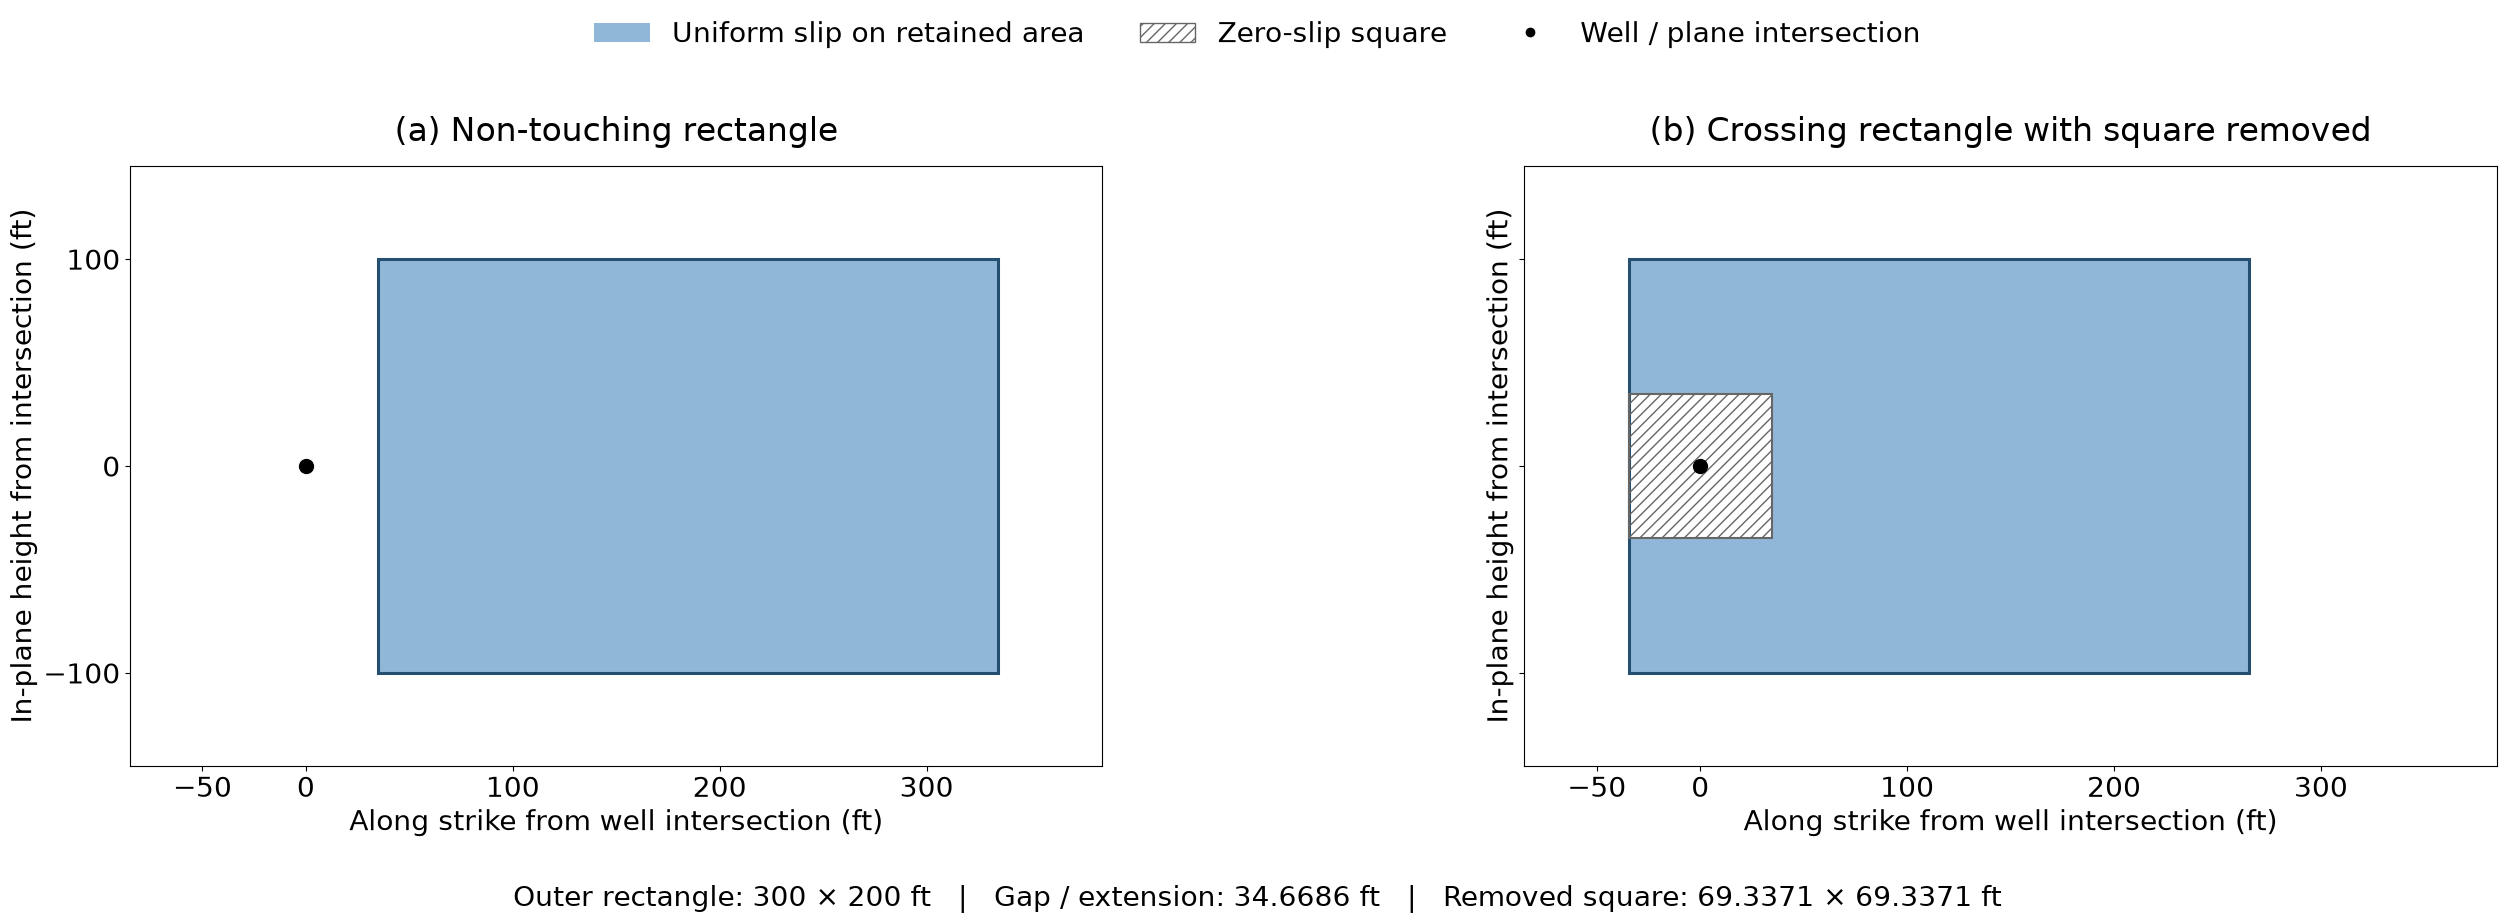

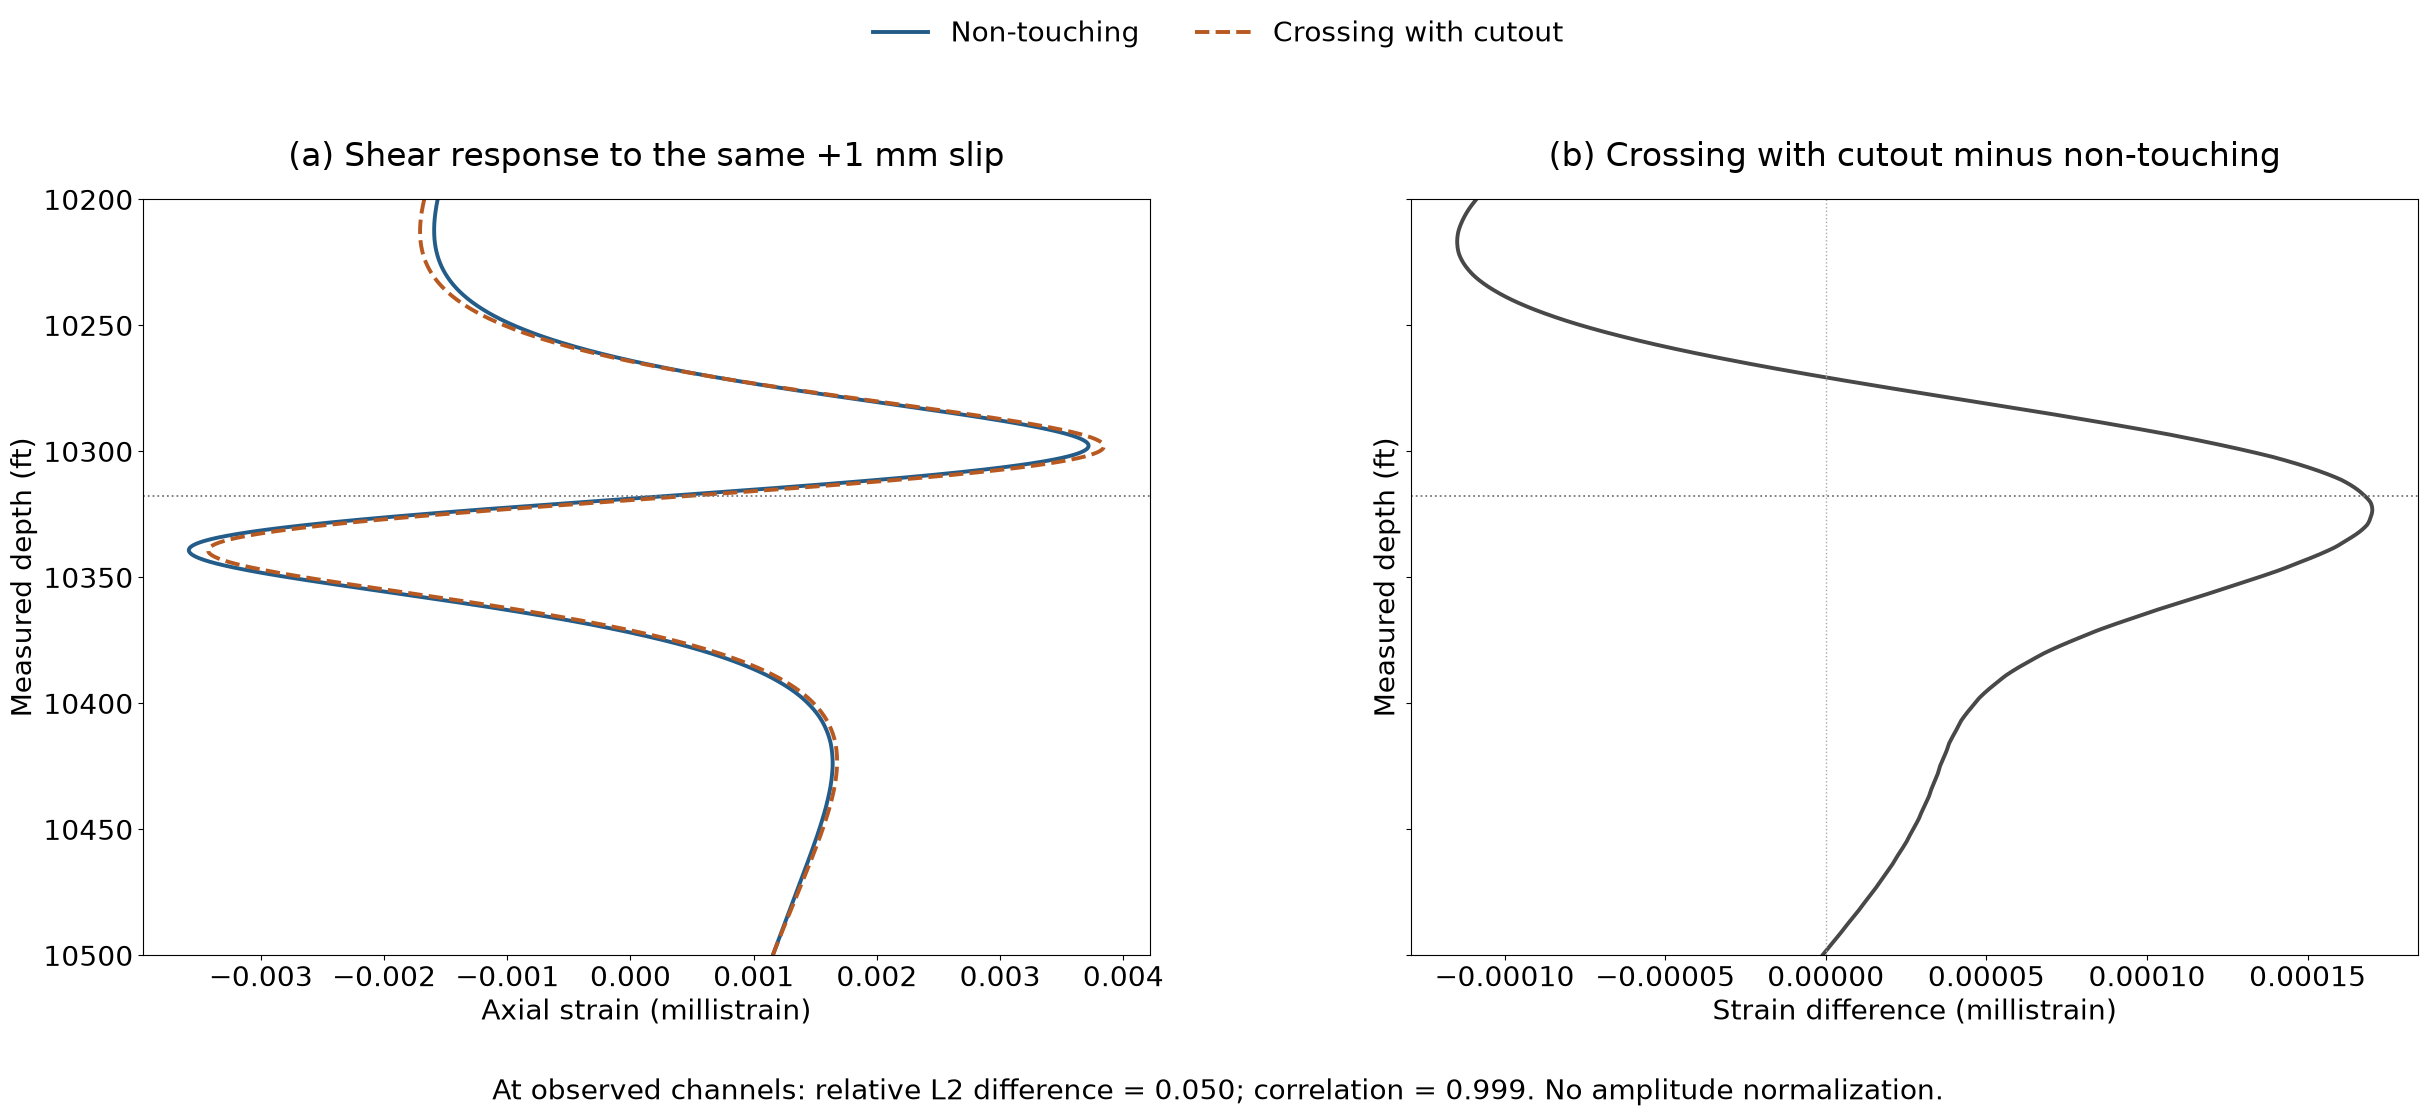

In [13]:
# Cell 15 | Modified 2026-09-22 00:41:24 MDT — Restrict rendered response lines to the displayed depth range.
# Cell 15 | Modified 2026-09-22 00:34:29 MDT — Geometry and same-slip response comparison
# Comparison figures: geometry first, then the response and its difference.
from matplotlib.patches import Rectangle,Patch


def save_case_comparison(fig,name,axes):
    """Check comparable side-by-side panels before normal figure exports."""
    fig.canvas.draw()
    qa_scripts=os.environ.get('FERVO_FIGURE_QA_SCRIPTS')
    if qa_scripts:
        if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
        from audit_panel_alignment import require_matplotlib_panel_alignment
        require_matplotlib_panel_alignment(fig,axes=list(axes),json_out=OUT/f'{name}_alignment.json',strict=True)
    save_figure(fig,name)


fig,axes=plt.subplots(1,2,figsize=(28,10),sharex=True,sharey=True)
fig.subplots_adjust(left=.06,right=.98,bottom=.20,top=.80,wspace=.18)
for ax,case,title in zip(axes,['non_touching','crossing_cutout'],['(a) Non-touching rectangle','(b) Crossing rectangle with square removed']):
    for a,b,c,d in rectangles[case]:
        ax.add_patch(Rectangle((a,c),b-a,d-c,facecolor='#90B7D8',edgecolor='none'))
    a,b=(GAP_FT,300+GAP_FT) if case=='non_touching' else (-GAP_FT,300-GAP_FT)
    ax.add_patch(Rectangle((a,-100),b-a,200,fill=False,edgecolor='#244F70',lw=2.2))
    if case=='crossing_cutout':
        ax.add_patch(Rectangle((-GAP_FT,-GAP_FT),2*GAP_FT,2*GAP_FT,facecolor='none',edgecolor='#666666',hatch='///',lw=1.5))
    ax.plot(0,0,'o',color='black',ms=10)
    ax.set(xlim=(-85,385),ylim=(-145,145),xlabel='Along strike from well intersection (ft)')
    ax.set_ylabel('In-plane height from intersection (ft)')
    ax.set_title(title,pad=18)
    ax.set_aspect('equal',adjustable='box')
    ax.set_xticks([-50,0,100,200,300]);ax.set_yticks([-100,0,100])
fig.legend(handles=[Patch(facecolor='#90B7D8',label='Uniform slip on retained area'),
                    Patch(facecolor='none',edgecolor='#666666',hatch='///',label='Zero-slip square'),
                    Line2D([],[],marker='o',ls='',color='black',label='Well / plane intersection')],
           loc='upper center',bbox_to_anchor=(.5,.97),ncol=3,frameon=False)
fig.text(.5,.06,f'Outer rectangle: 300 × 200 ft   |   Gap / extension: {GAP_FT:.4f} ft   |   Removed square: {2*GAP_FT:.4f} × {2*GAP_FT:.4f} ft',ha='center',fontsize=20)
save_case_comparison(fig,'small_shear_geometry_comparison',axes)

fig,axes=plt.subplots(1,2,figsize=(25,12),sharey=True)
fig.subplots_adjust(left=.07,right=.98,bottom=.17,top=.80,wspace=.26)
# Identical positive 1-mm source slip: display true amplitude differences.
factor=1e3/FT_TO_MM
# Clip only the rendered line arrays to the stated view; retain padded solver data.
shown=(full_md>=10200)&(full_md<=10500)
for k,label,color,style in [(0,'Non-touching','#245C89','-'),(1,'Crossing with cutout','#B75921','--')]:
    axes[0].plot(full_response[k,shown]*factor,full_md[shown],color=color,lw=2.8,ls=style,label=label)
axes[0].set_title('(a) Shear response to the same +1 mm slip',pad=24)
axes[0].set_xlabel('Axial strain (millistrain)');axes[0].set_ylabel('Measured depth (ft)')
axes[1].plot((full_response[1,shown]-full_response[0,shown])*factor,full_md[shown],color='#484848',lw=2.8)
axes[1].axvline(0,color='#aaaaaa',lw=1,ls=':')
axes[1].set_title('(b) Crossing with cutout minus non-touching',pad=24)
axes[1].set_xlabel('Strain difference (millistrain)');axes[1].set_ylabel('Measured depth (ft)')
for ax in axes:
    ax.set_ylim(10500,10200)
    ax.axhline(hit['md_ft'],color='#777777',ls=':',lw=1.3)
    ax.ticklabel_format(axis='x',style='plain',useOffset=False)
fig.legend(*axes[0].get_legend_handles_labels(),loc='upper center',bbox_to_anchor=(.5,.97),ncol=2,frameon=False)
fig.text(.5,.05,f"At observed channels: relative L2 difference = {comparison['relative_L2_difference_same_positive_slip']:.3f}; correlation = {comparison['correlation']:.3f}. No amplitude normalization.",ha='center',fontsize=20)
save_case_comparison(fig,'small_shear_response_comparison',axes)


### Cell 16 | Pressure, slip evolution and large waterfall diagnostics

Show injection pressure with recorded stage numbers, slip histories, and both observed and simulated waterfalls.

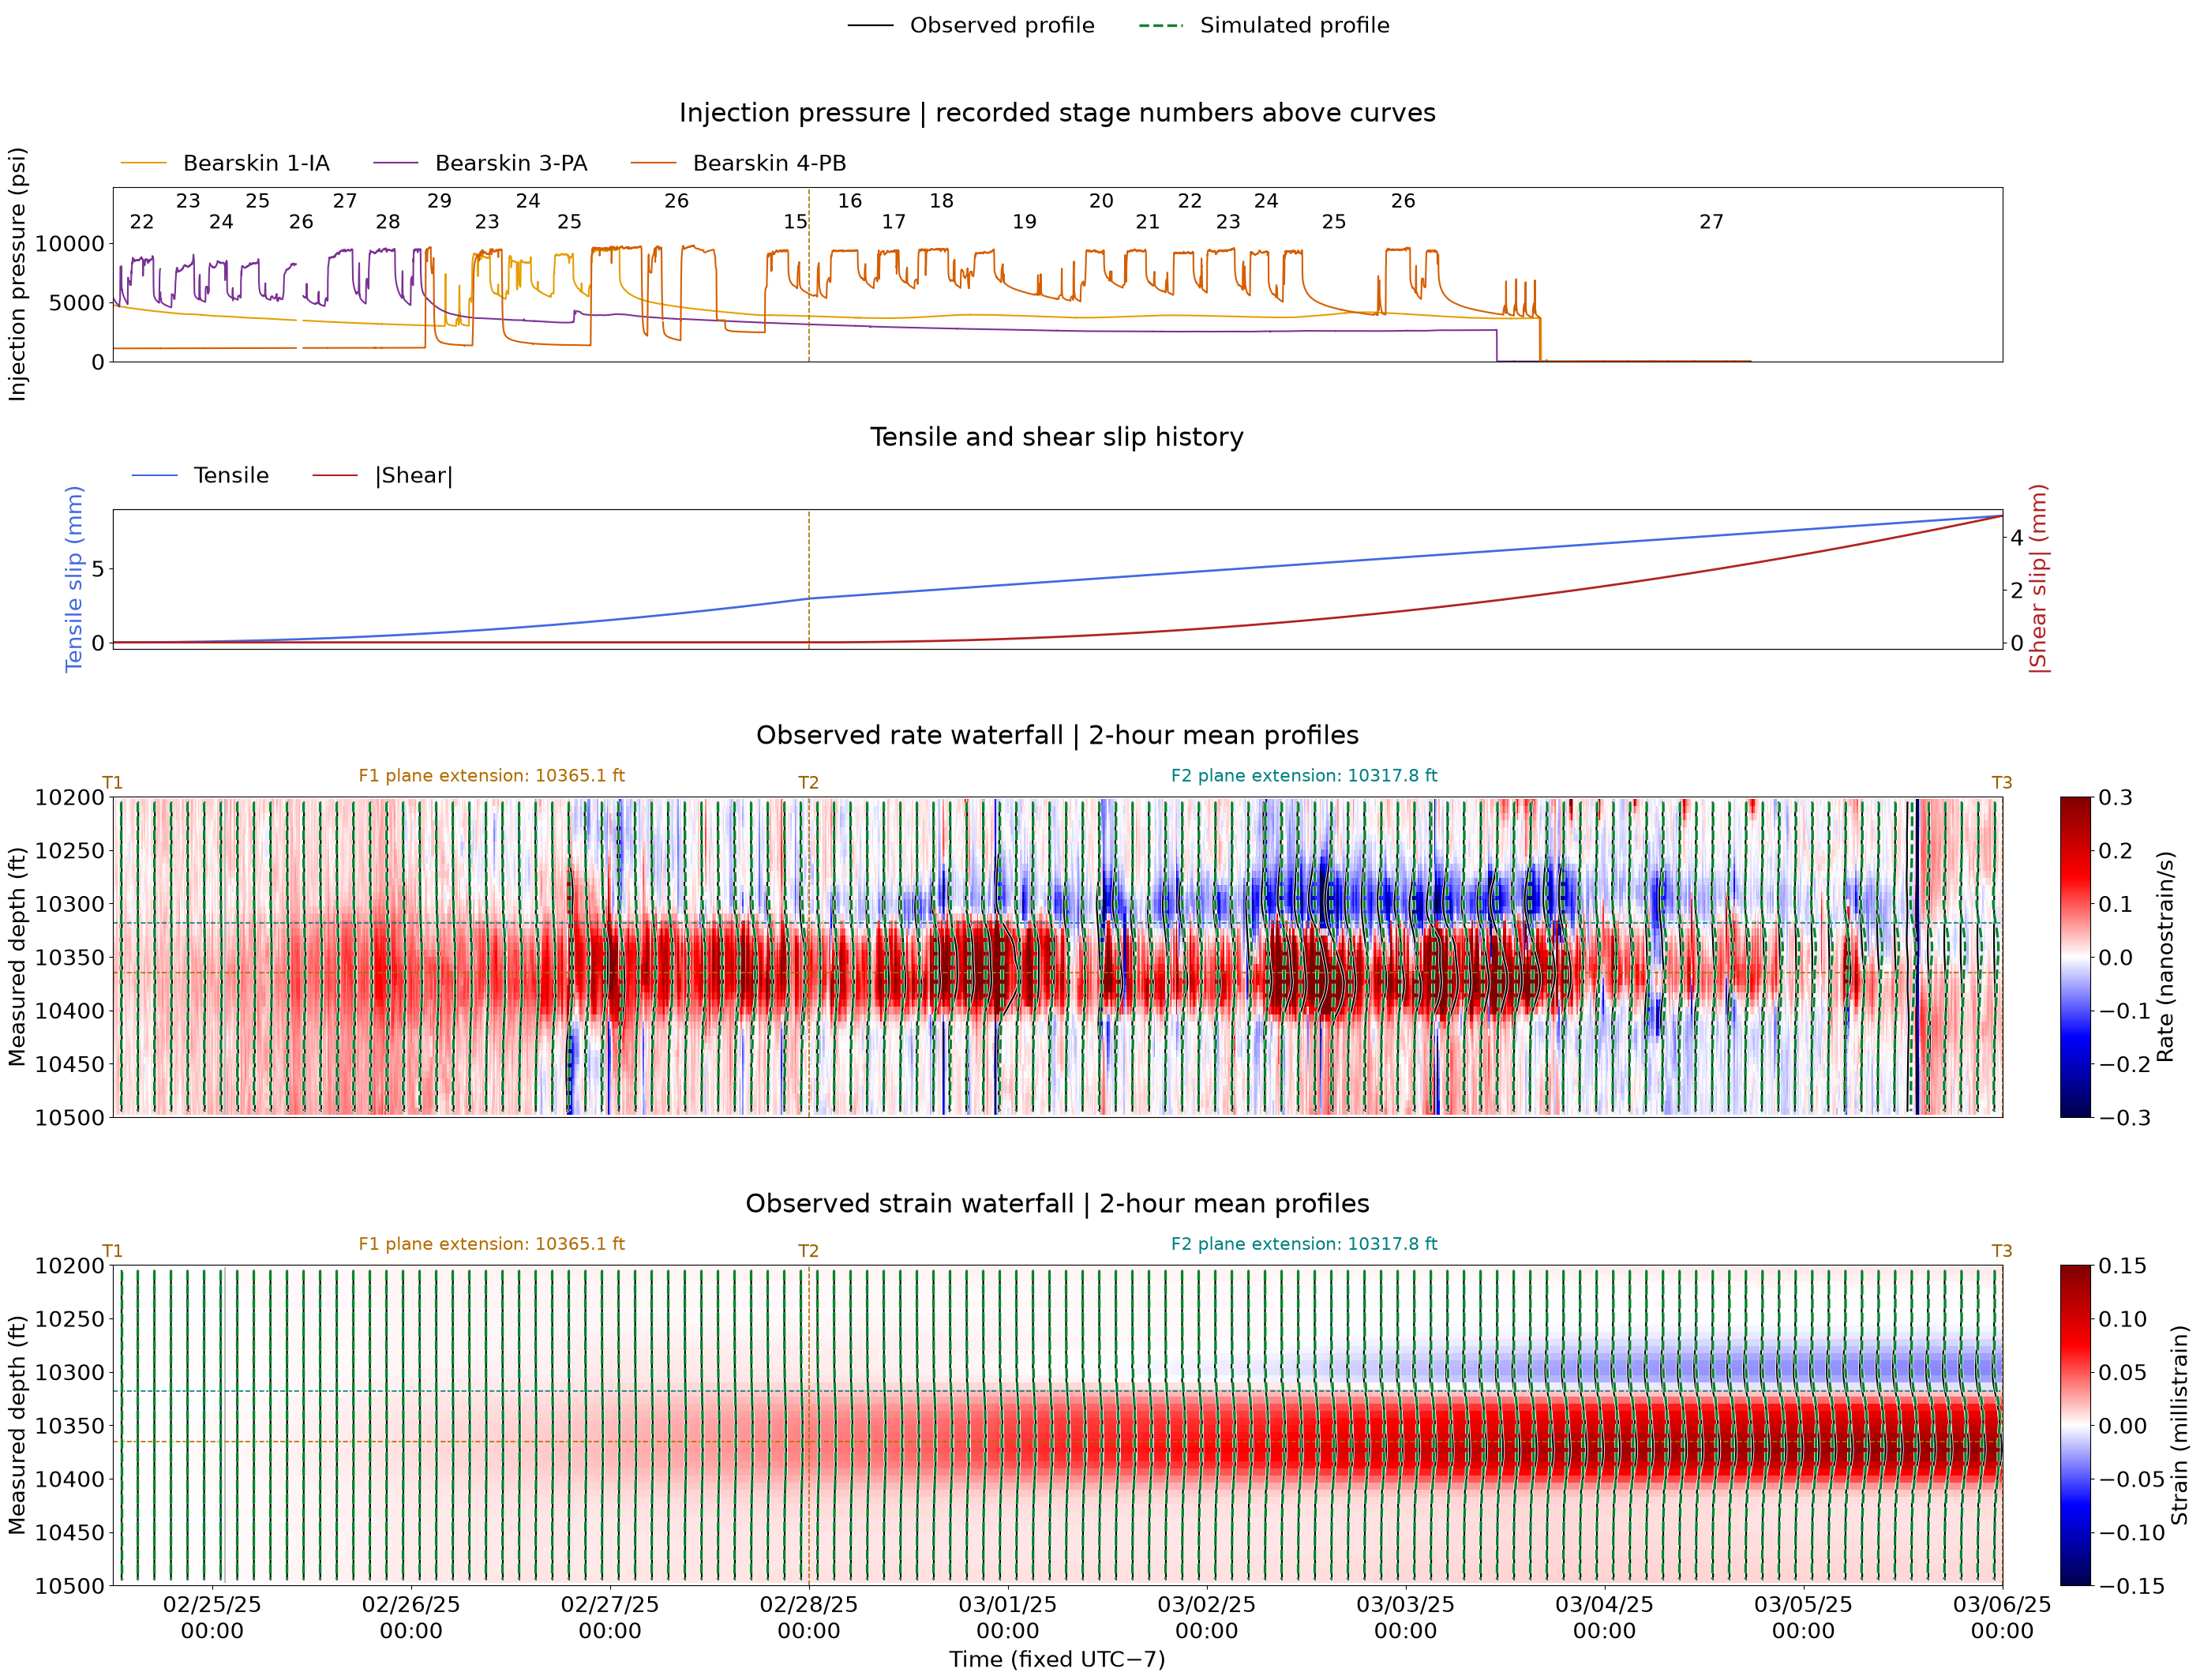

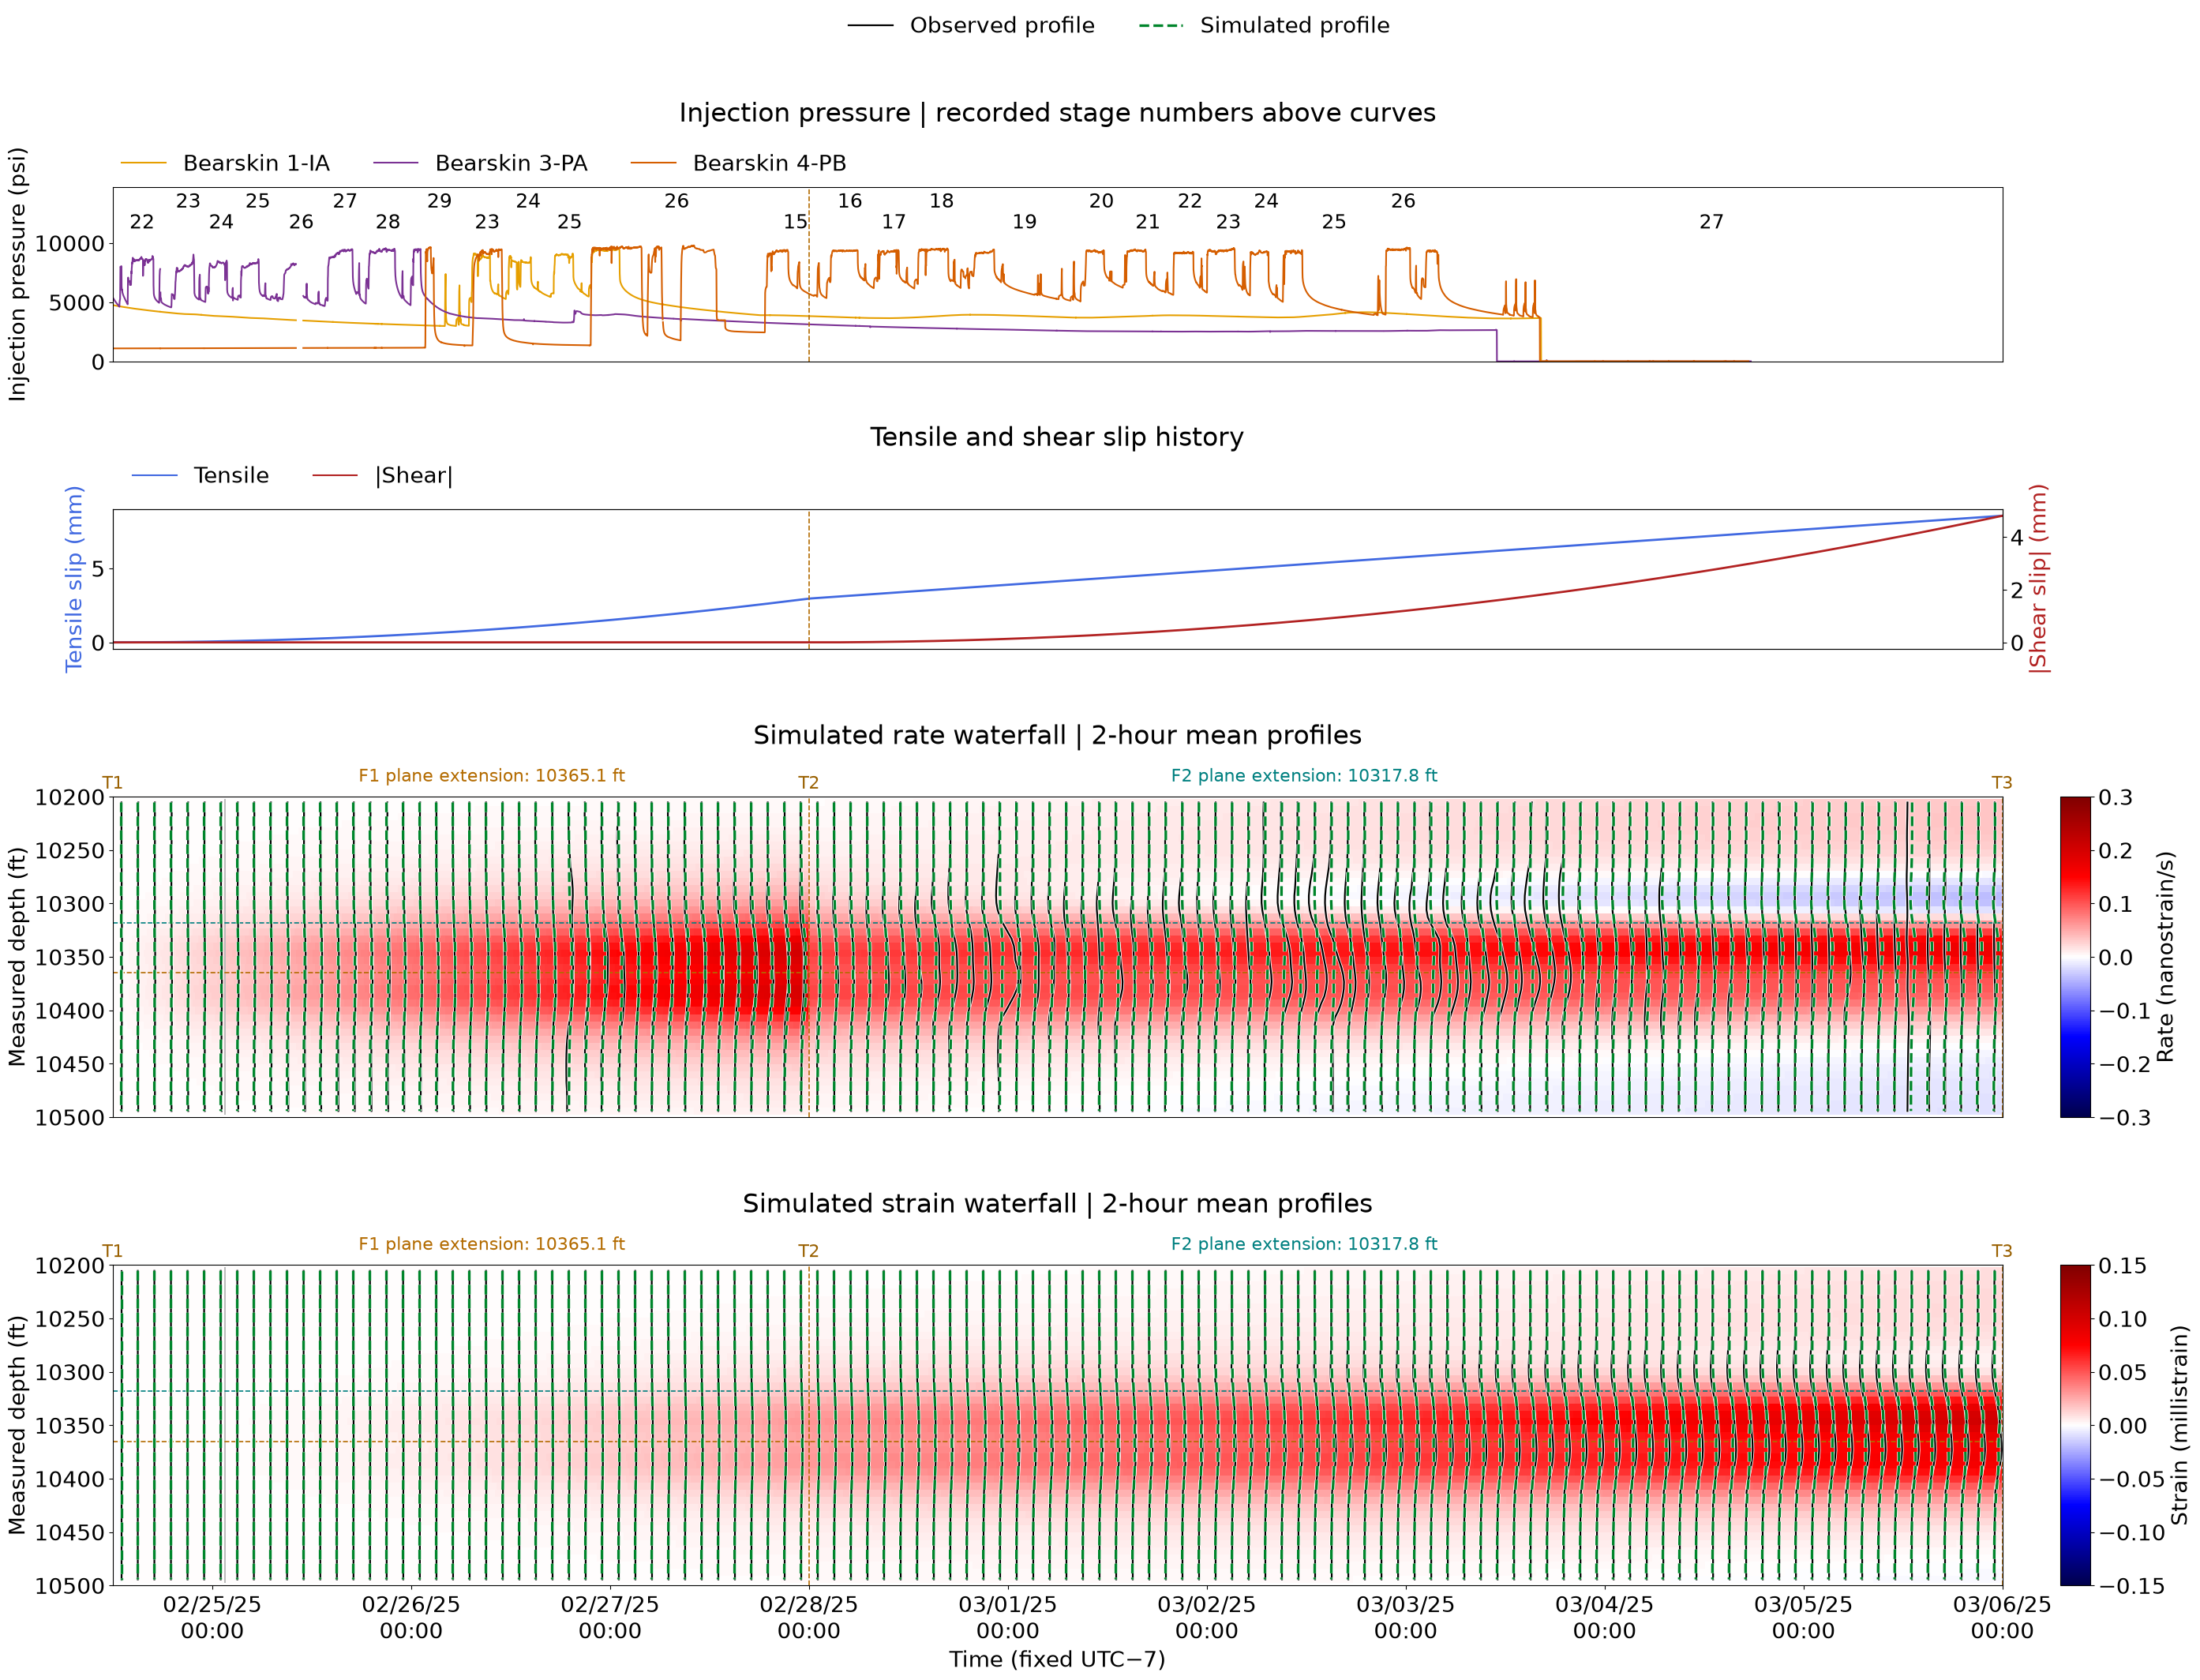

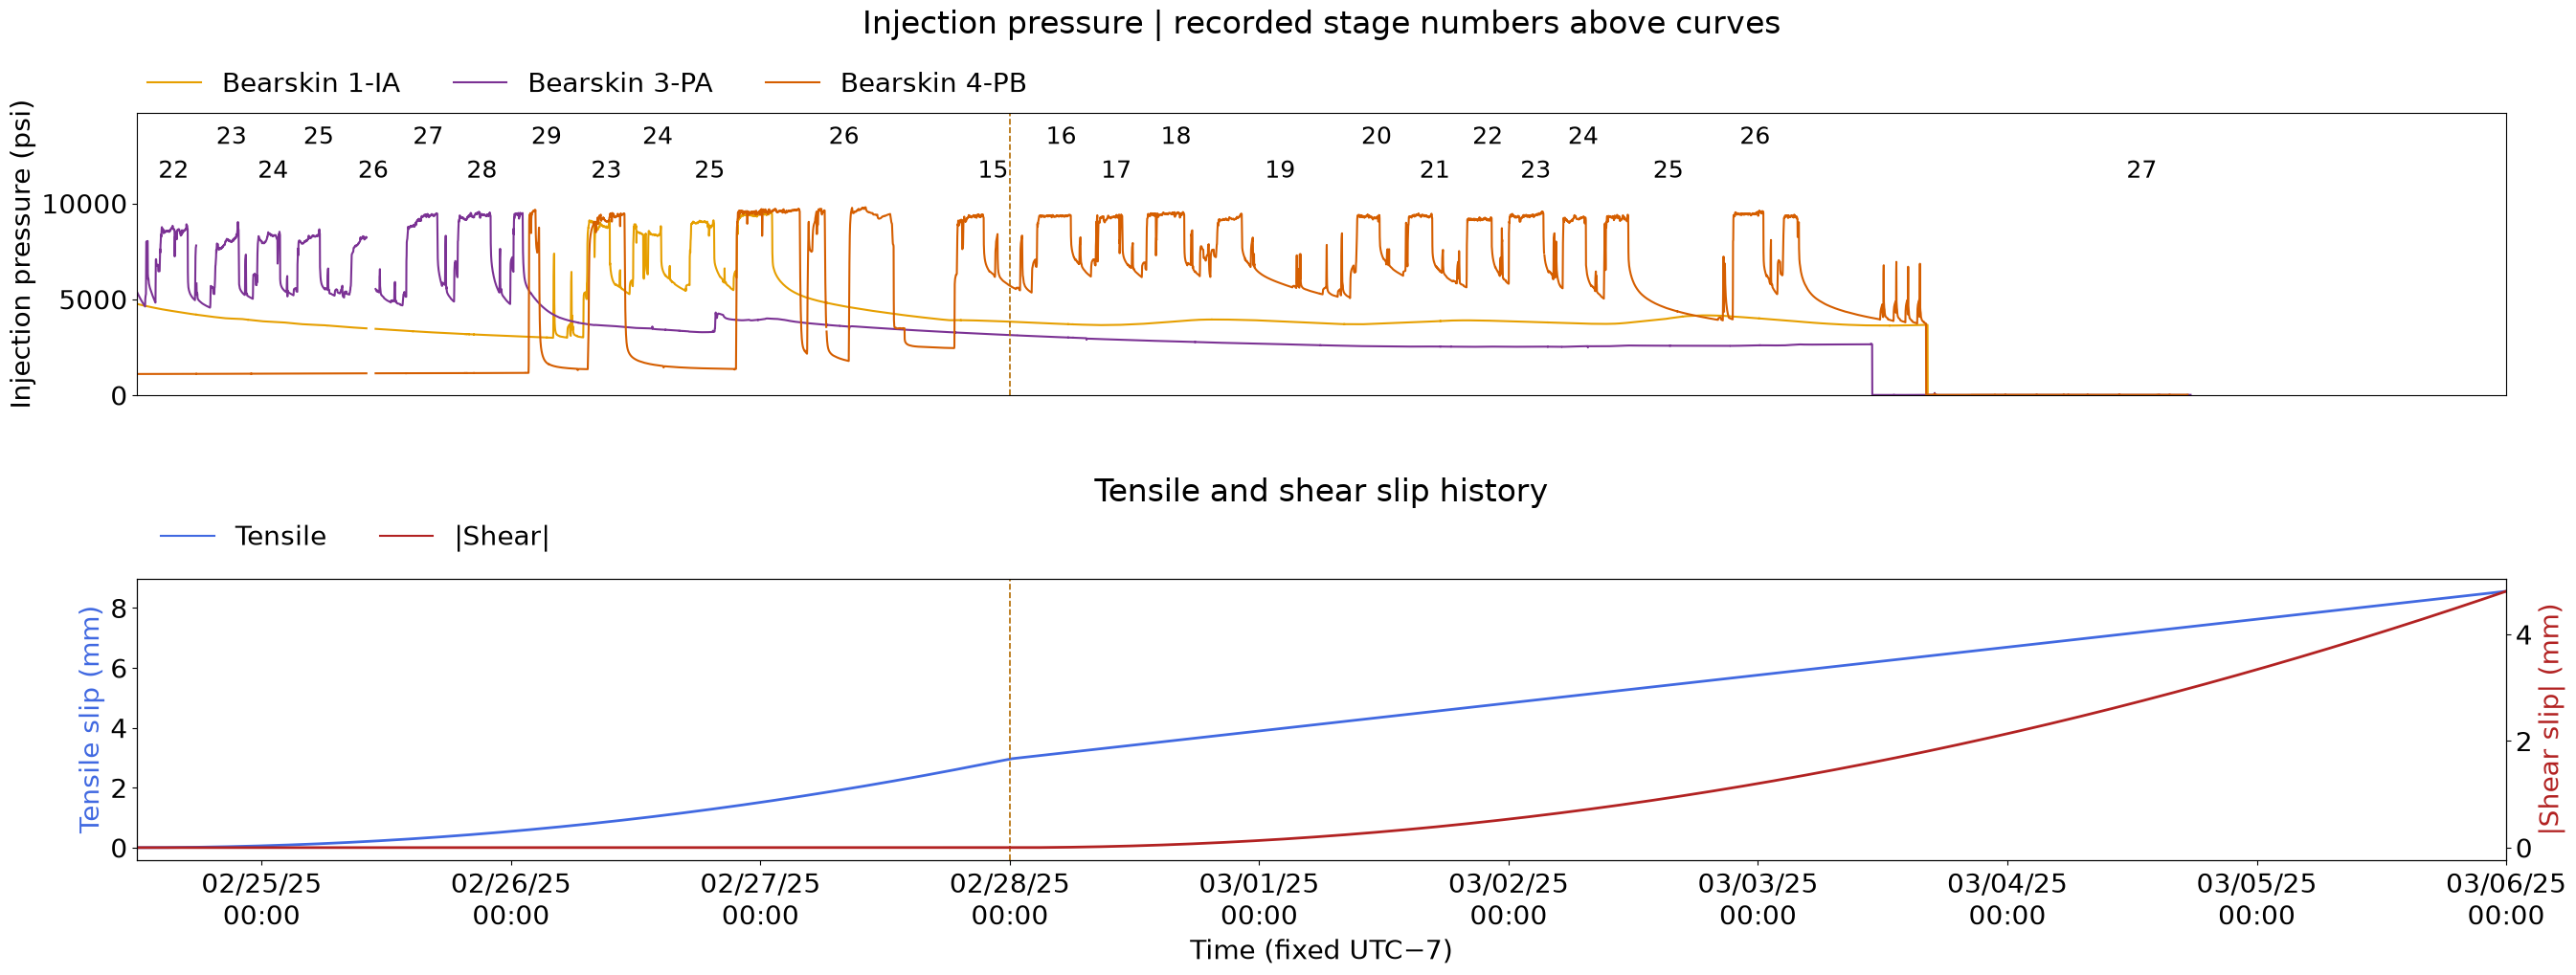

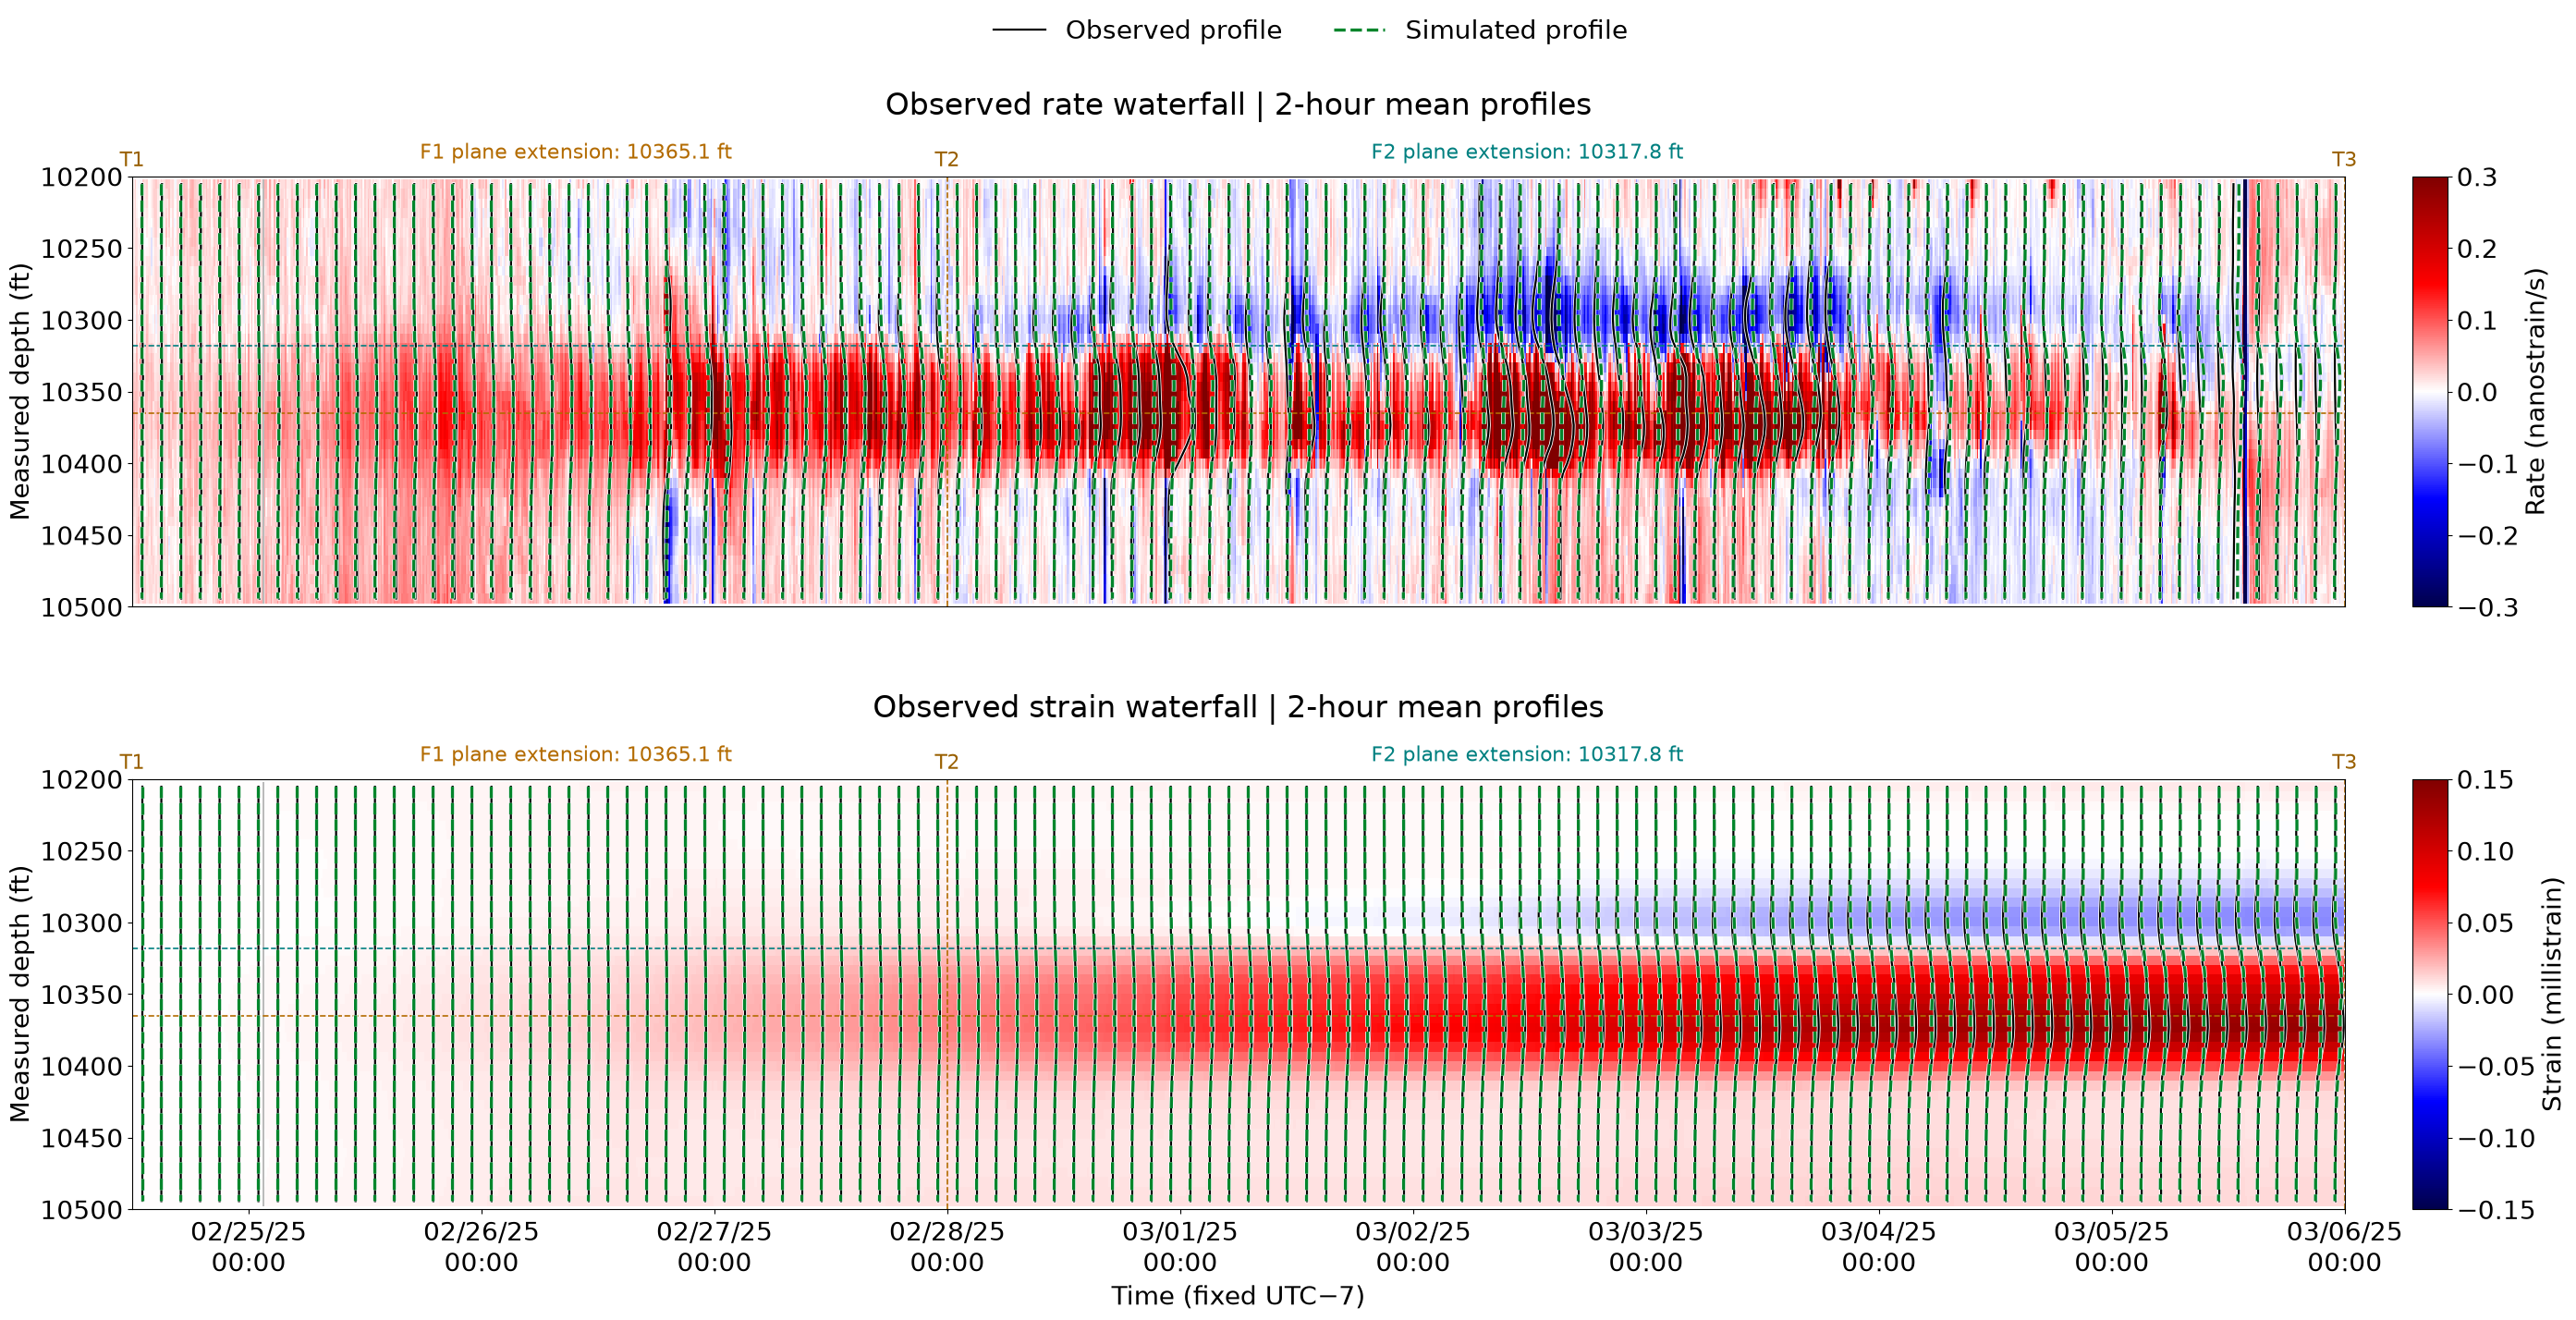

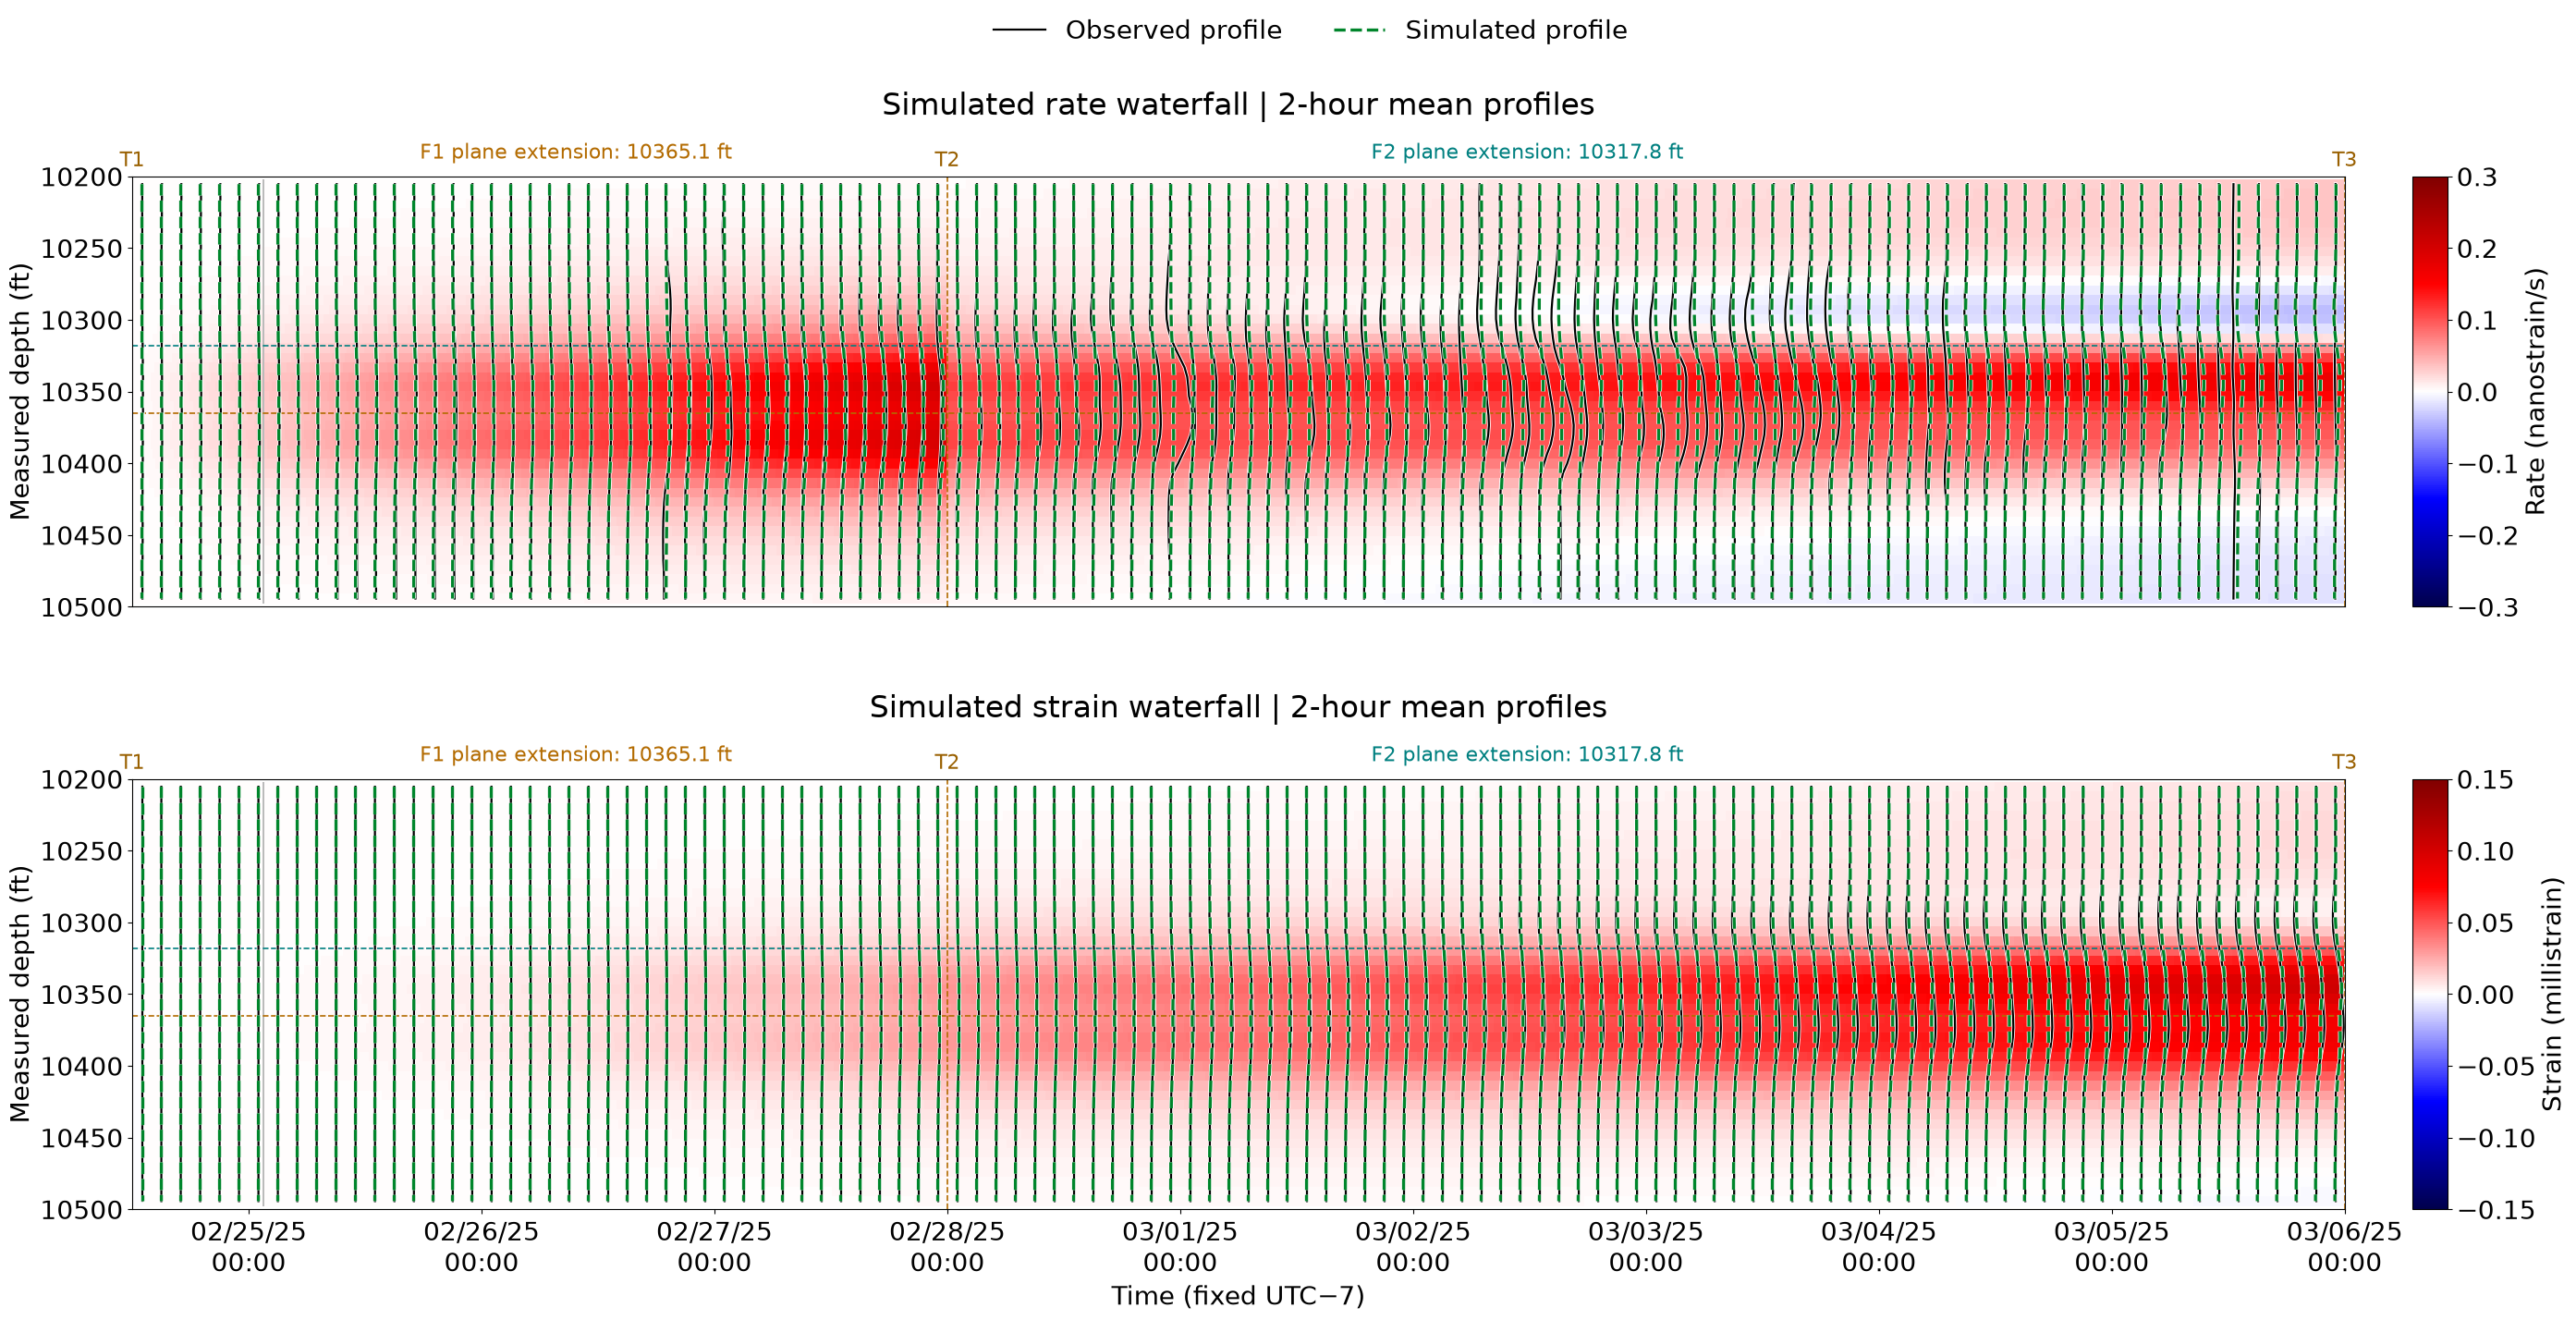

In [14]:
# Cell 16 | Modified 2026-09-22 00:34:29 MDT — Adapt this existing section to the isolated crossing_cutout experiment.
# Cell 16 | Modified 2026-09-20 22:37:10 MDT — Pressure, slip evolution and large waterfall diagnostics
# Purpose: Show injection pressure with recorded stage numbers, slip histories, and both observed and simulated waterfalls.
injection=pressure_data()
injection.to_csv(OUT/'injection_pressure.csv',index=False)
plot_summary(obs,baseline,injection,f'Baseline_{FIT_TARGET}_fit_prescribed_time_laws')
plot_summary(obs,baseline,injection,f'Baseline_{FIT_TARGET}_fit_prescribed_time_laws',background='simulated')
plot_pressure_slip(obs,baseline,injection,f'Baseline_{FIT_TARGET}_fit_prescribed_time_laws')
plot_comparison(obs,baseline,'baseline')

### Cell 17 | Geometry: wells, microseismicity and the small shear source

Run after Cell 12. Show all valid catalog events in T1–T3 (2025, fixed UTC−7), four well trajectories, the half-height tensile ellipse and this case’s actual rectangular shear support in map, side, gun-barrel and 3D views. Coordinates and source dimensions are in feet. The zero-slip notch is left unfilled. Cell 15 provides the small-source close-up; the dashed diameter here marks only F1. Exports PNG/PDF/SVG to this case’s output folder.

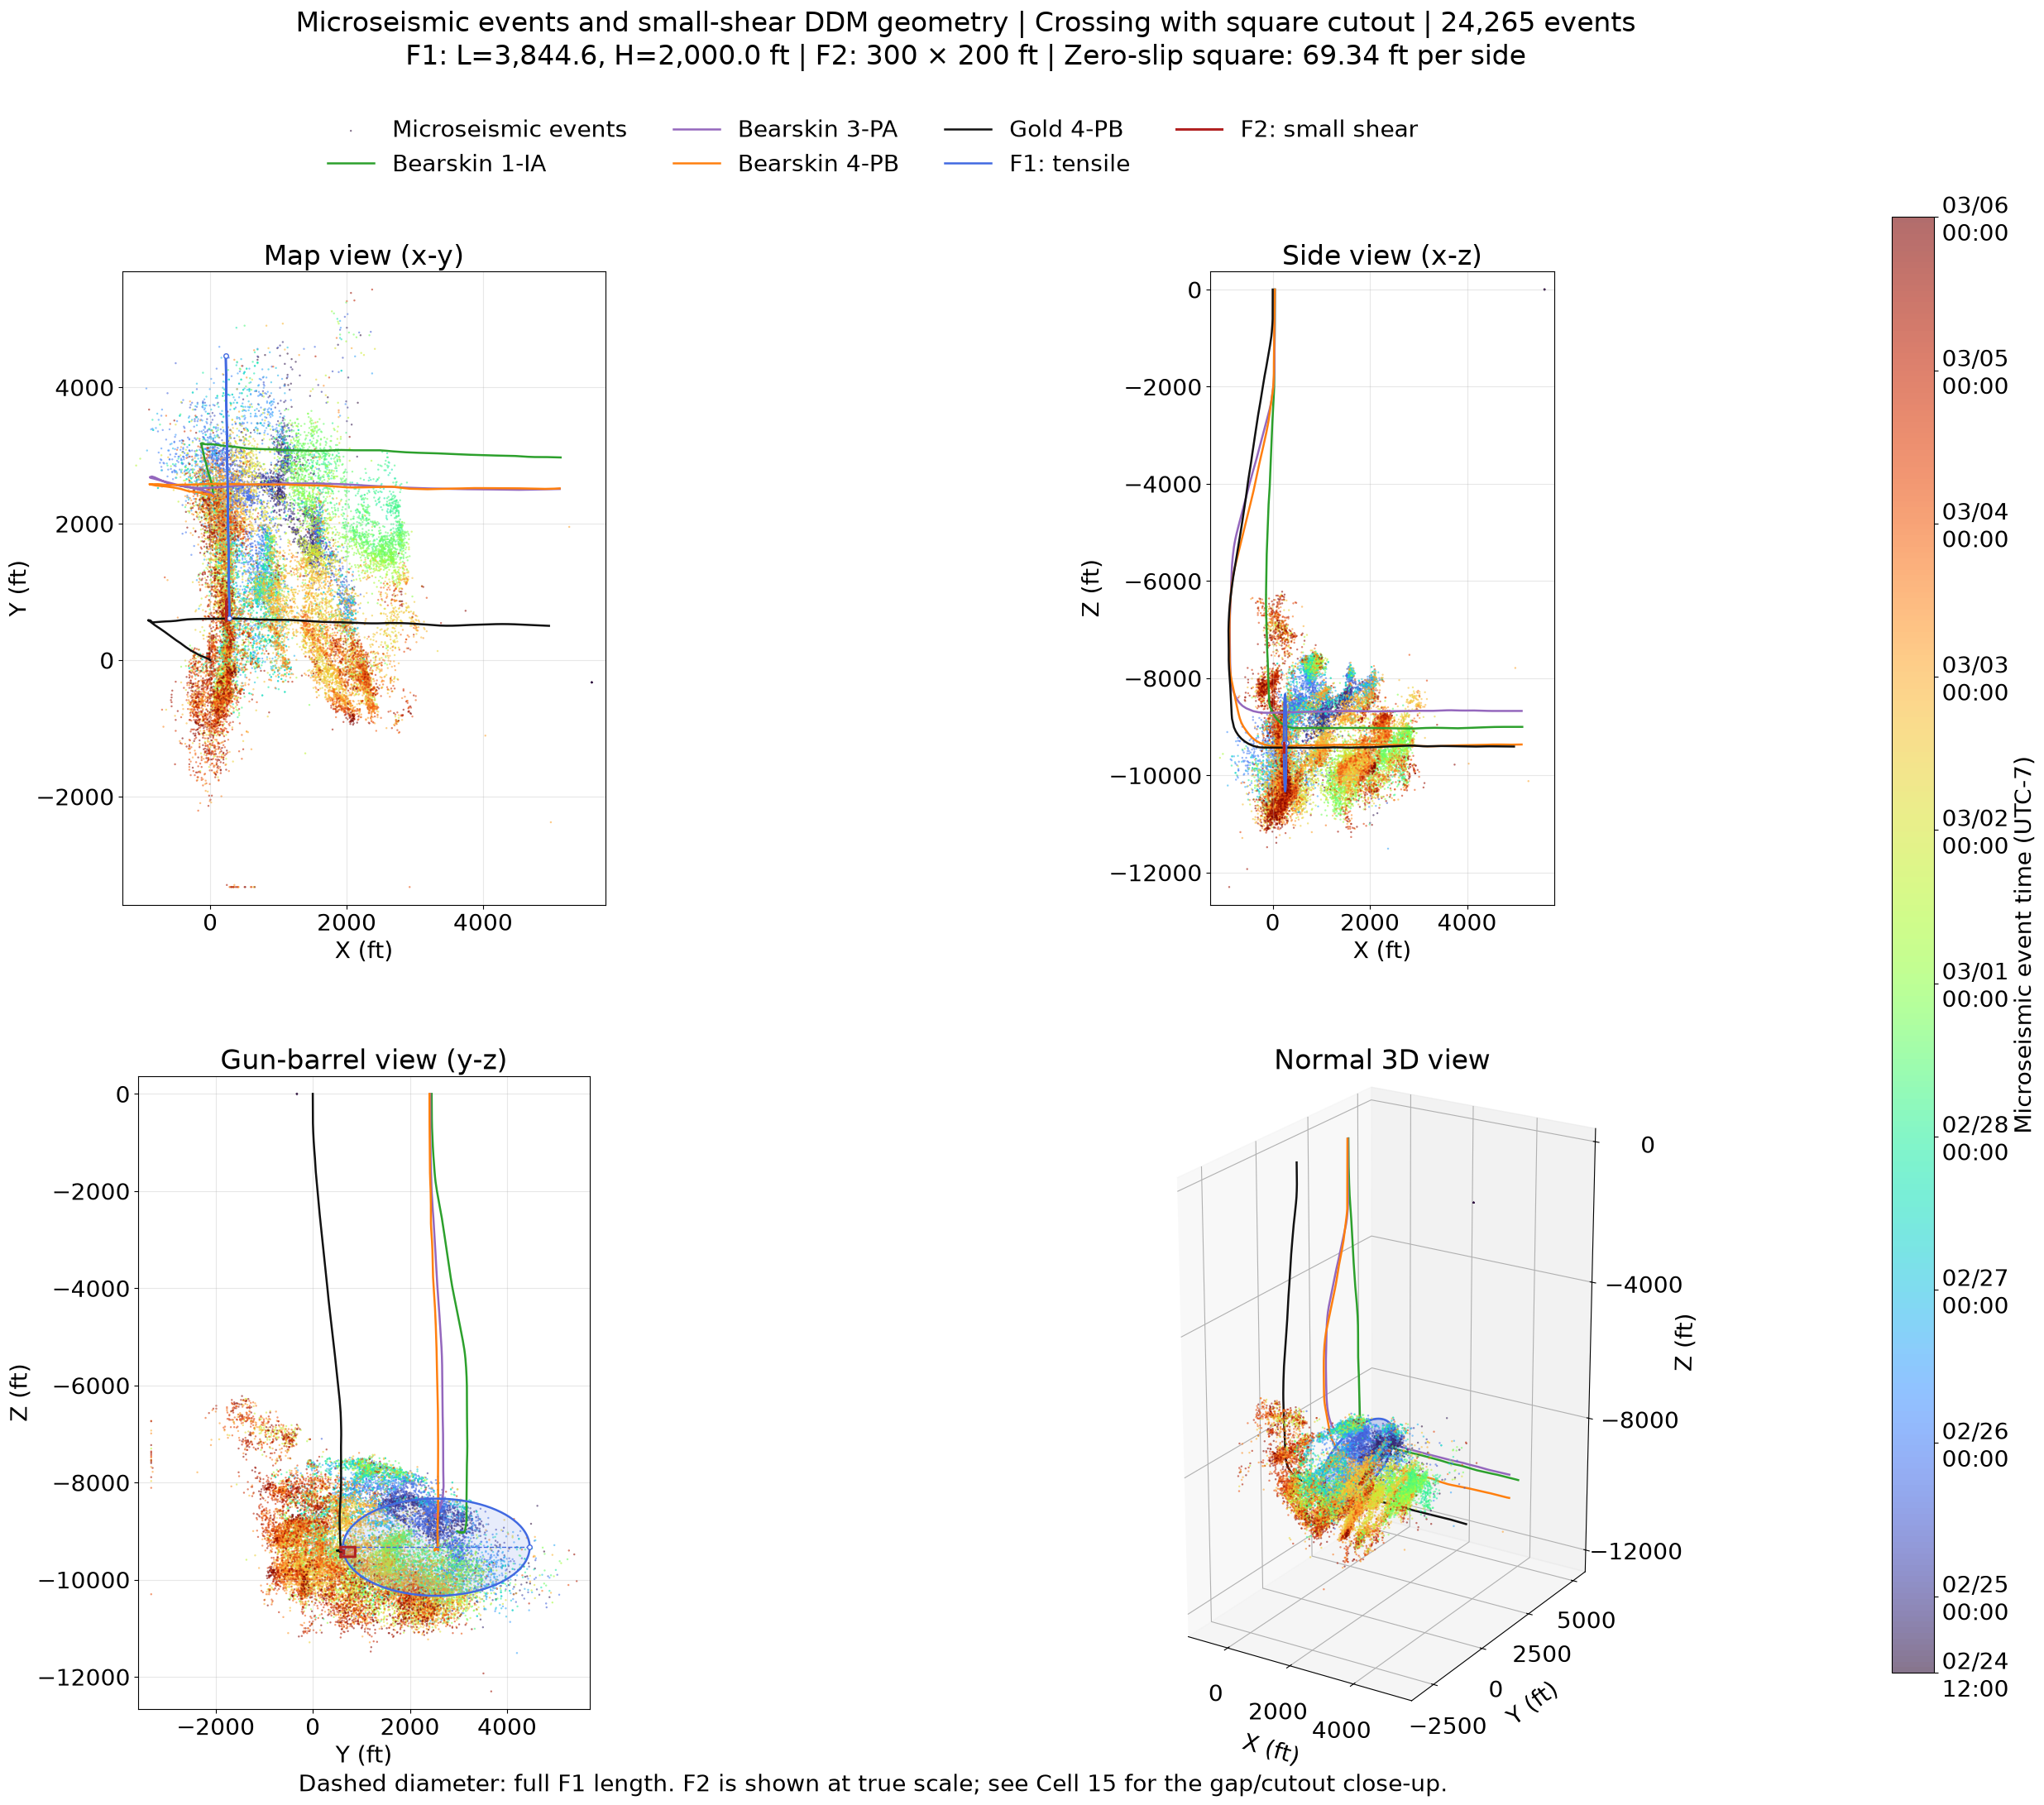

In [15]:
# Cell 17 | Modified 2026-09-22 22:49:18 MDT — Use half-height F1 and verify matching recomputed responses.
# Cell 17 | Modified 2026-09-22 17:50:17 MDT — Add four-view microseismic/well geometry with the actual small shear support.
# Purpose: Show the half-height F1 ellipse and the true F2 rectangle/cutout in global feet.
import geometry_diagnostics
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.ticker import MaxNLocator

context=geometry_diagnostics.load_geometry_context(
    V1.parent.parent/'data/Microseismic Catalog/Microseismic_202502_202505_feet.csv',
    V1.parent.parent/'data/Well Geometries',T1,T3)
# Reuse the reference context/layout for F1 only: F2 is not an ellipse.
fig=geometry_diagnostics.microseismic_geometry(geometries[:1],context=context,shape='ellipse')
fig.set_size_inches(28,22)
axes=fig.axes[:4]

def shear_global(uv):
    """Use the same inverse rotation and origin as the rectangular source model."""
    uv=np.asarray(uv,float)
    local=np.column_stack([uv,np.zeros(len(uv))])
    xyz=np.asarray(hit['global_ft'])+np.linalg.solve(R,local.T).T
    np.testing.assert_allclose((R@(xyz-np.asarray(hit['global_ft'])).T).T,local,atol=1e-8)
    return xyz

# The crossing case's boundary follows the notch; never fill the zero-slip square.
gap=GAP_FT
if CASE=='non_touching':
    boundary_uv=[(gap,-100),(300+gap,-100),(300+gap,100),(gap,100),(gap,-100)]
    case_label='Non-touching'
else:
    assert CASE=='crossing_cutout'
    boundary_uv=[(-gap,-100),(300-gap,-100),(300-gap,100),(-gap,100),
                 (-gap,gap),(gap,gap),(gap,-gap),(-gap,-gap),(-gap,-100)]
    case_label='Crossing with square cutout'
shear_boundary=shear_global(boundary_uv)
shear_tiles=[shear_global([(a,c),(b,c),(b,d),(a,d)]) for a,b,c,d in rectangles[CASE]]
# Check that the displayed polygon area equals the modeled active rectangle area.
uv=np.asarray(boundary_uv)
shown_area=.5*abs(np.sum(uv[:-1,0]*uv[1:,1]-uv[1:,0]*uv[:-1,1]))
model_area=sum((b-a)*(d-c) for a,b,c,d in rectangles[CASE])
assert np.isclose(shown_area,model_area)
for ax,(a,b) in zip(axes[:3],[(0,1),(0,2),(1,2)]):
    for xyz in shear_tiles:
        ax.fill(xyz[:,a],xyz[:,b],color='firebrick',alpha=.25,lw=0,zorder=5)
    ax.plot(shear_boundary[:,a],shear_boundary[:,b],color='firebrick',lw=2.2,zorder=6,
            label='F2: small shear')
ax3=axes[3]
ax3.add_collection3d(Poly3DCollection(shear_tiles,facecolor='firebrick',edgecolor='none',alpha=.35))
ax3.plot(*shear_boundary.T,color='firebrick',lw=2.2)
for axis in [ax3.xaxis,ax3.yaxis,ax3.zaxis]:
    axis.set_major_locator(MaxNLocator(4))
    axis.set_tick_params(labelsize=20,pad=10)
ax3.zaxis.set_tick_params(pad=30)
ax3.set_xlabel('X (ft)',labelpad=20)
ax3.set_ylabel('Y (ft)',labelpad=20)
ax3.set_zlabel('Z (ft)',labelpad=50)
# Keep the single shared legend and full, unsampled T1–T3 event cloud.
for legend in list(fig.legends): legend.remove()
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.46,.945),ncol=4,frameon=False)
f1=geometries[0]
fig.suptitle(
    f'Microseismic events and small-shear DDM geometry | {case_label} | {len(context["events"]):,} events\n'
    f'F1: L={f1["length_ft"]:,.1f}, H={f1["height_ft"]:,.1f} ft | F2: 300 × 200 ft'
    +(f' | Zero-slip square: {2*gap:.2f} ft per side' if CASE=='crossing_cutout' else f' | Along-strike gap: {gap:.2f} ft'),
    y=.995,fontsize=24)
fig.text(.46,.015,'Dashed diameter: full F1 length. F2 is shown at true scale; see Cell 15 for the gap/cutout close-up.',
         ha='center',fontsize=20)
save_figure(fig,'small_shear_microseismic_geometry')
